# 1. What is Matplotlib?

**Matplotlib** is a Python library used to create static, animated, and interactive visualizations.

The most commonly used module is:

```python
import matplotlib.pyplot as plt
```

`pyplot` provides functions such as:

- `plot()`
- `scatter()`
- `bar()`
- `hist()`
- `pie()`
- `boxplot()`
- `stem()`
- `stackplot()`
- `errorbar()`
- `imshow()`
- `subplot()`
- `subplots()`

## Why do you need Matplotlib?

A dataset contains numbers and categories, but raw tables can hide patterns.

Visualization helps us answer questions such as:

- Are exam scores normally distributed?
- Which department has higher average performance?
- Does study time relate to exam score?
- Are there unusual/outlier students?
- Does attendance relate to performance?
- Are male and female students distributed similarly?
- How does enrollment vary over time?
- Which numerical variables move together?

### Matplotlib in the ML workflow

```text
Raw Data
   ↓
Data Cleaning
   ↓
EDA + Visualization
   ↓
Feature Understanding
   ↓
Feature Engineering
   ↓
Model Building
   ↓
Model Evaluation
```

EDA is therefore not decoration. It helps us understand the data before building an ML model.


# Matplotlib EDA — Student Performance Dataset


**Dataset → Question → Appropriate Plot → Observation → Business/ML Insight**

### What students will learn

1. What Matplotlib is
2. Why visualization is important in Data Science and Machine Learning
3. Matplotlib architecture and basic syntax
4. Figure and Axes
5. Plot customization
6. Univariate analysis
7. Bivariate analysis
8. Multivariate analysis
9. Distribution analysis
10. Outlier analysis
11. Categorical analysis
12. Numerical relationship analysis
13. Time-based visualization
14. Correlation visualization
15. Common plot-selection rules
16. How to interpret plots
17. How EDA supports ML
18. End-to-end Matplotlib EDA on the student dataset

> **Important:** In the next session, Seaborn can be used to create many of these visualizations more easily and with better statistical defaults. This notebook deliberately focuses on **Matplotlib first** so students understand the foundation.


Raw Data
   ↓
Data Cleaning
   ↓
EDA ← Explore and understand
   ↓
Data Analysis ← Answer questions and find insights
   ↓
Conclusions / Decisions

EDA is not completely separate from data analysis. It is one important part of the broader data-analysis process.

# 2. Advantages of Matplotlib

### Major advantages

- Free and open source
- Works directly with NumPy and Pandas
- Highly customizable
- Supports many plot types
- Useful for exploratory analysis
- Useful for reports and presentations
- Works with machine-learning workflows
- Gives precise control over figure size, labels, ticks, legends and annotations
- Forms the foundation for higher-level visualization libraries such as Seaborn

### Limitations

- Some plots require more code than Seaborn
- Statistical plots are less convenient than Seaborn
- Attractive styling often requires manual customization
- Complex visualizations can become verbose

### Matplotlib vs Seaborn

| Matplotlib | Seaborn |
|---|---|
| Low-level/foundation plotting library | Higher-level statistical visualization library |
| Very high customization | Easier statistical plots |
| Works directly with arrays | Works especially well with DataFrames |
| More manual code | Often less code |
| Foundation for many Python visualizations | Built on Matplotlib |


# 3. Main Plot Categories

We will classify EDA into three important groups.

## A. Univariate Analysis

**One variable at a time.**

Purpose:
- Understand distribution
- Understand frequency
- Identify spread
- Identify central tendency
- Identify outliers

Examples:
- Histogram
- Box plot
- Bar chart
- Pie chart
- Stem plot

---

## B. Bivariate Analysis

**Two variables at a time.**

Purpose:
- Study relationship
- Compare variables
- Find trends
- Understand association

Examples:
- Scatter plot
- Line plot
- Grouped bar chart
- Area plot

---

## C. Multivariate Analysis

**Three or more variables.**

Purpose:
- Understand interactions
- Compare multiple dimensions
- Discover patterns that are hidden in two-variable analysis

Examples:
- Scatter plot with color/group
- Bubble chart
- Multiple line plots
- Stacked bar chart
- Heatmap
- 3D scatter plot
- 3D surface plot

---

# Plot Selection Cheat Sheet

| Question | Recommended Plot |
|---|---|
| How is one numerical variable distributed? | Histogram |
| Are there outliers? | Box plot |
| How many records belong to each category? | Bar chart |
| What percentage belongs to each category? | Pie chart |
| How do two numerical variables relate? | Scatter plot |
| How does a value change over time? | Line plot |
| Compare two categorical groups | Grouped bar |
| Compare several numerical variables | Multiple line |
| Show cumulative contribution | Stacked bar / area |
| Show relationships between many numeric variables | Heatmap |
| Show 3 numeric dimensions | 3D scatter |
| Show 3D relationship as a surface | 3D surface |


# Plot Classification by Number of Variables

Plots can also be classified according to the number of variables being analyzed.

| Analysis Type | Number of Variables | Analytical Purpose | Common Plots | Example |
|---|---:|---|---|---|
| **Univariate Analysis** | 1 | Understand the distribution, frequency, spread, and characteristics of a single variable | Histogram, Bar Plot, Pie Chart, Box Plot, Violin Plot, Stem Plot | Distribution of Exam Scores |
| **Bivariate Analysis** | 2 | Analyze the relationship, comparison, or association between two variables | Scatter Plot, Line Plot, Bar Plot, Box Plot, 2D Histogram, Hexbin Plot, Contour Plot | Study Hours vs Exam Score |
| **Multivariate Analysis** | 3 or more | Analyze interactions, relationships, patterns, or comparisons involving multiple variables | Grouped Bar Plot, Stacked Bar Plot, Stack Plot, Contour Plot, Streamplot | Study Hours + Attendance + Assignment Score + Exam Score |


In [2]:
%pip install matplotlib
import matplotlib.pyplot as plt

%pip install numpy
import numpy as np

%pip install pandas
import pandas as pd



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# 4. Import Libraries and Load the Cleaned Dataset

We are intentionally using the **cleaned dataset** from the previous preprocessing session.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

# Load cleaned dataset
df = pd.read_csv("Student_Performance_Cleaned.csv")

# Convert date column
df["Enrollment_Date"] = pd.to_datetime(
    df["Enrollment_Date"],
    errors="coerce"
)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully.
Shape: (60, 13)


,Student_ID,Name,Age,Gender,Department,Attendance,Study_Hours,Assignment_Score,Exam_Score,City,Enrollment_Date,Fee_Status,Placement_Status
0,1001,Ravi,21,Female,Data Science,84.0,5.5,63,78,Visakhapatnam,2026-01-05,Paid,Placed
1,1002,Priya,23,Male,Cloud,76.1,8.4,61,99,Chennai,2026-01-08,Paid,Placed
2,1003,Arun,23,Female,Python,98.9,2.0,63,70,Hyderabad,2026-01-11,Paid,Placed
3,1004,Meena,21,Male,Data Science,97.9,3.6,72,64,Visakhapatnam,2026-01-14,Paid,Not Placed
4,1005,Kiran,22,Male,Ai,85.4,2.8,70,76,Vijayawada,2026-01-17,Paid,Placed


# 5. First EDA Step — Understand the Dataset

Before creating charts, inspect the structure.

Important commands:

- `shape`
- `head()`
- `tail()`
- `info()`
- `describe()`
- `dtypes`
- `nunique()`
- `value_counts()`

### Why?

A good data scientist does not start plotting blindly.

First understand:
- number of rows
- number of columns
- numerical columns
- categorical columns
- date columns
- possible target variables


In [4]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Info:")
df.info()

print("\nNumerical Summary:")
display(df.describe())

print("\nUnique values per column:")
display(df.nunique())


Shape: (60, 13)

Columns:
['Student_ID', 'Name', 'Age', 'Gender', 'Department', 'Attendance', 'Study_Hours', 'Assignment_Score', 'Exam_Score', 'City', 'Enrollment_Date', 'Fee_Status', 'Placement_Status']

Data Types:
Student_ID                   int64
Name                           str
Age                          int64
Gender                         str
Department                     str
Attendance                 float64
Study_Hours                float64
Assignment_Score             int64
Exam_Score                   int64
City                           str
Enrollment_Date     datetime64[us]
Fee_Status                     str
Placement_Status               str
dtype: object

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Student_ID        60 non-null     int64         
 1   Name              60 non-null     str   

,Student_ID,Age,Attendance,Study_Hours,Assignment_Score,Exam_Score,Enrollment_Date
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60
mean,1030.500000,21.700000,86.155000,4.666667,72.283333,80.266667,2026-04-03 12:00:00
min,1001.000000,20.000000,68.600000,1.500000,45.000000,53.000000,2026-01-05 00:00:00
25%,1015.750000,20.750000,79.275000,3.225000,60.000000,70.000000,2026-02-18 06:00:00
50%,1030.500000,22.000000,85.400000,4.300000,71.000000,80.000000,2026-04-03 12:00:00
75%,1045.250000,23.000000,94.425000,6.250000,83.250000,95.250000,2026-05-17 18:00:00
max,1060.000000,24.000000,98.900000,8.400000,98.000000,99.000000,2026-07-01 00:00:00
std,17.464249,1.305789,8.465872,2.038749,15.755646,14.565884,NaN



Unique values per column:


Student_ID          60
Name                57
Age                  5
Gender               2
Department           4
Attendance          53
Study_Hours         39
Assignment_Score    34
Exam_Score          30
City                 5
Enrollment_Date     60
Fee_Status           2
Placement_Status     2
dtype: int64

# 6. Matplotlib Basic Anatomy

A standard Matplotlib visualization has:

```text
Figure
 └── Axes
      ├── Title
      ├── X-axis
      ├── Y-axis
      ├── Data
      ├── Legend
      └── Grid
```

Recommended modern structure:

```python
fig, ax = plt.subplots()

ax.plot(x, y)

ax.set_title("Title")
ax.set_xlabel("X")
ax.set_ylabel("Y")

plt.show()
```

### Figure vs Axes

- **Figure** = complete canvas
- **Axes** = actual plotting area

This distinction becomes important when creating multiple plots.


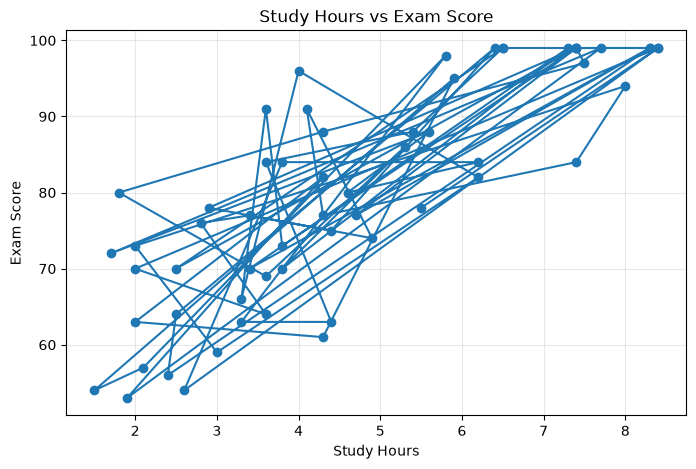

In [5]:
# Basic Matplotlib example using our dataset

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df["Study_Hours"],
    df["Exam_Score"],
    marker="o"
)

ax.set_title("Study Hours vs Exam Score")
ax.set_xlabel("Study Hours")
ax.set_ylabel("Exam Score")

ax.grid(True, alpha=0.3)

plt.show()


# 7. Matplotlib Formatting Essentials

Matplotlib provides many parameters that help us control the appearance, readability, and presentation of graphs.

These formatting parameters do not change the actual data. They change **how the data is displayed visually**.

The important formatting parameters covered in this section are:

- `figsize`
- `marker`
- `linestyle`
- `linewidth`
- `alpha`
- `label`
- `color`
- `edgecolor`
- `bins`
- `rotation`
- `grid()`
- `legend()`
- `xlim()`
- `ylim()`

---

figsize   → How big is my graph?

marker    → How do individual points look?

linestyle → How does my line look?

linewidth → How thick is my line?

alpha     → How transparent is my graph element?

label     → What is the name of my data?

color     → What color should my data use?

edgecolor → What color should the border have?

bins      → How should histogram data be grouped?

rotation  → How should my labels be rotated?

grid()    → Should I show reference lines?

legend()  → How do I explain different data series?

xlim()    → What X-axis range should I display?

ylim()    → What Y-axis range should I display?

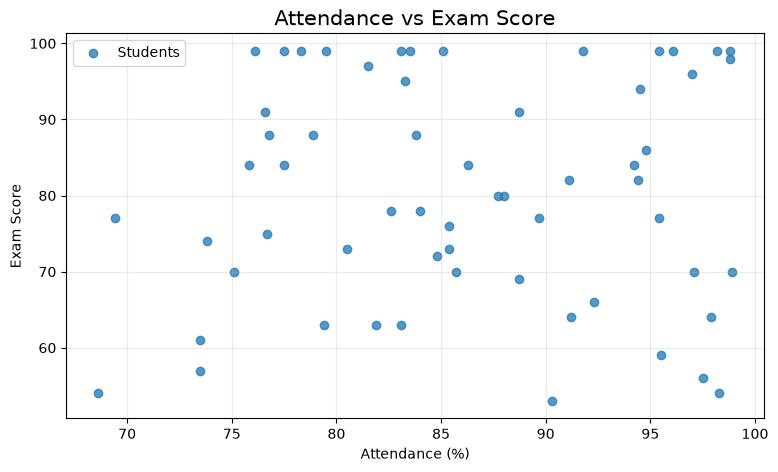

In [6]:

plt.figure(figsize=(9,5))

plt.scatter(
    df["Attendance"],
    df["Exam_Score"],
    alpha=0.75,
    label="Students"
)

plt.title("Attendance vs Exam Score", fontsize=15)
plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")
plt.legend()
plt.grid(True, alpha=0.25)

plt.show()


# 8. UNIVARIATE ANALYSIS

## What is Univariate Analysis?

Univariate means analyzing **one variable at a time**.

For numerical variables, we usually study:
- minimum
- maximum
- mean
- median
- spread
- distribution
- skewness
- outliers

For categorical variables, we study:
- frequency
- percentage
- most common category

We will use several Matplotlib plots.


# 9. Histogram — Univariate Numerical Analysis

## What is a histogram?

A histogram groups numerical values into intervals called **bins** and displays how many observations fall into each interval.

### When to use

Use a histogram when you want to understand:
- distribution
- concentration
- spread
- skewness
- possible multiple peaks

### ML applications

Histograms are useful before:
- Normalization → bring values to a common range.
- Standardization → express values based on how far they are from the mean.
- transformation
- outlier treatment
- feature selection

Examples:
- Age
- Attendance
- Study Hours
- Exam Score


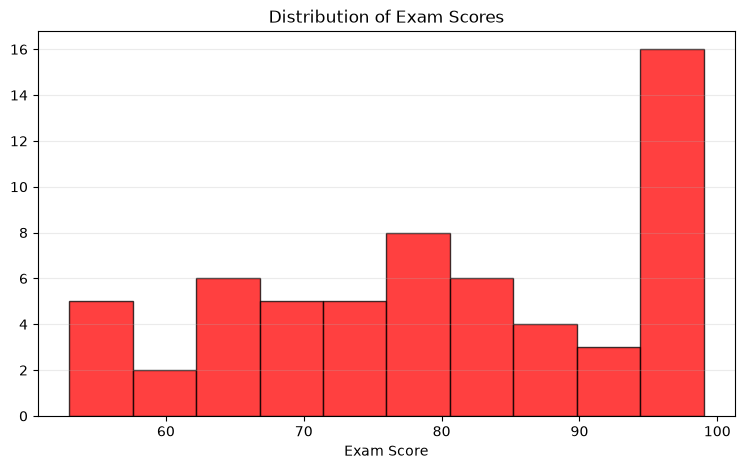

In [7]:
# Histogram: Exam Score

plt.figure(figsize=(9, 5))

plt.hist(
    df["Exam_Score"],
    #a bin is a range of values that groups data points together
    bins=10,
    edgecolor="black",
    alpha=0.75,
    color="red"
)

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
#plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.25)

plt.show()


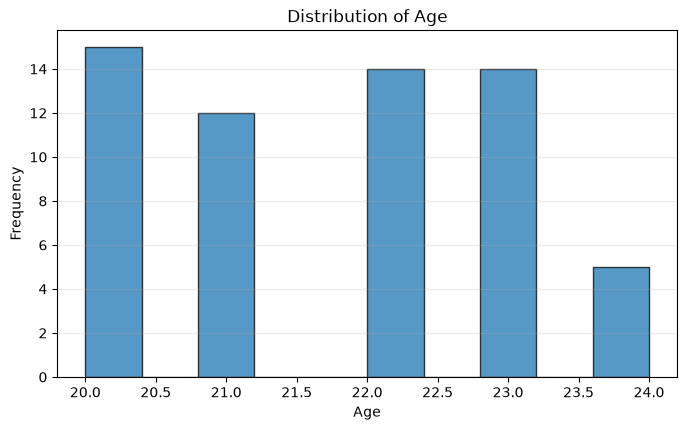

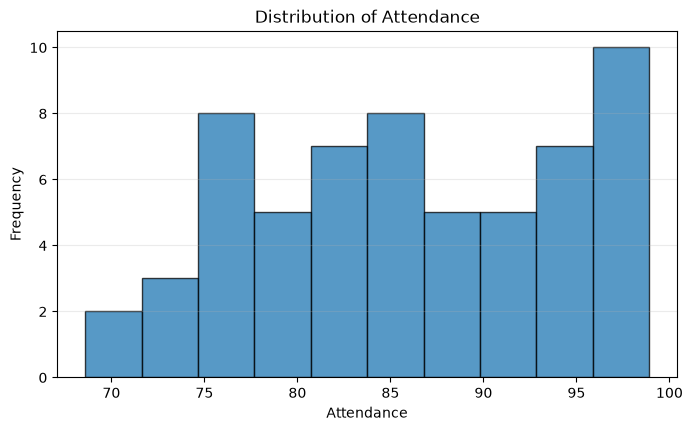

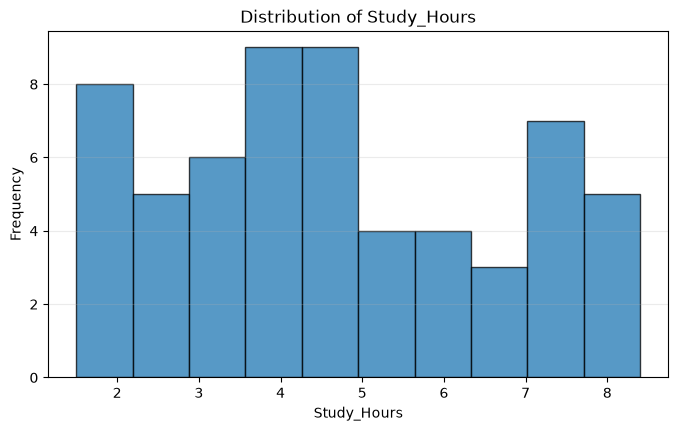

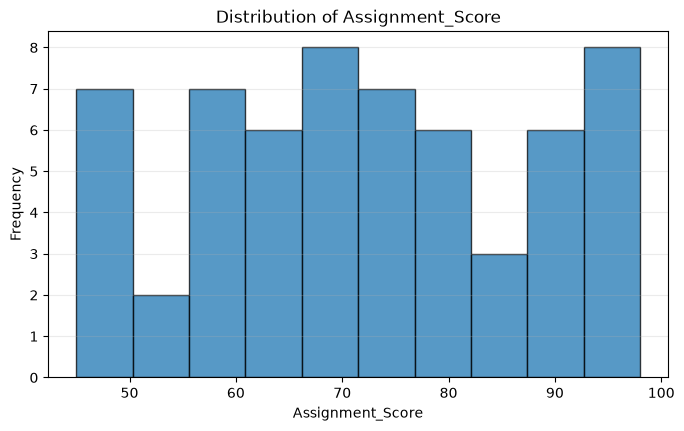

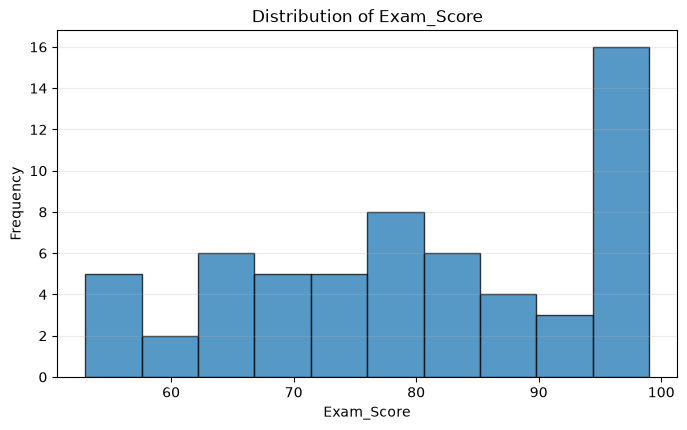

In [8]:
# Histograms for important numerical variables

numeric_cols = [
    "Age",
    "Attendance",
    "Study_Hours",
    "Assignment_Score",
    "Exam_Score"
]

for col in numeric_cols:
    plt.figure(figsize=(8, 4.5))
    plt.hist(df[col], bins=10, edgecolor="black", alpha=0.75)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.grid(axis="y", alpha=0.25)
    plt.show()


# 10. Box Plot — Univariate Outlier Analysis

A box plot summarizes:

- Minimum
- Q1
- Median
- Q3
- Maximum
- Potential outliers

### When to use

Use a box plot when you need to:
- detect outliers
- compare spread
- compare distributions between groups

### ML importance

Outliers can affect:
- mean
- linear regression  -  a supervised learning algorithm used mainly to predict a continuous numerical value.
- distance-based algorithms -how close or far data points are from each other.
- scaling
- clustering

Therefore box plots are very useful during preprocessing.


C:\Users\pmariyamma\AppData\Local\Temp\ipykernel_10752\2640557233.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


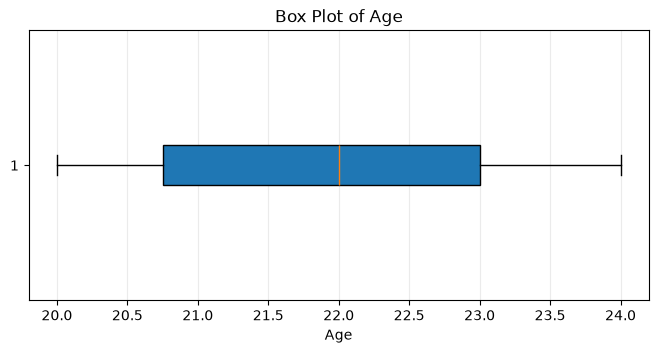

C:\Users\pmariyamma\AppData\Local\Temp\ipykernel_10752\2640557233.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


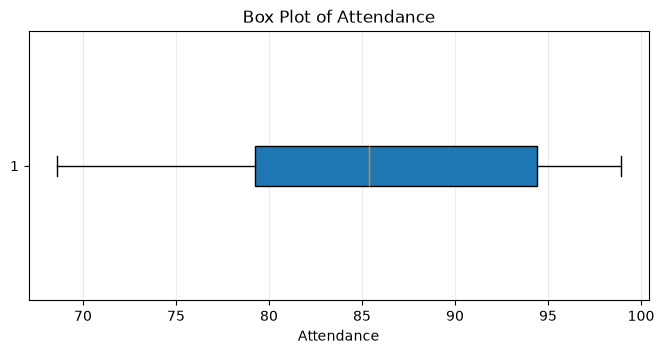

C:\Users\pmariyamma\AppData\Local\Temp\ipykernel_10752\2640557233.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


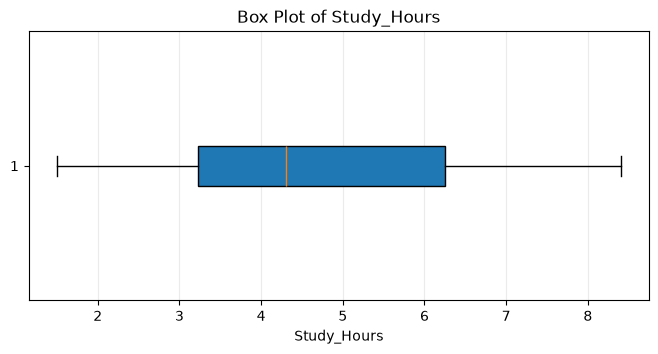

C:\Users\pmariyamma\AppData\Local\Temp\ipykernel_10752\2640557233.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


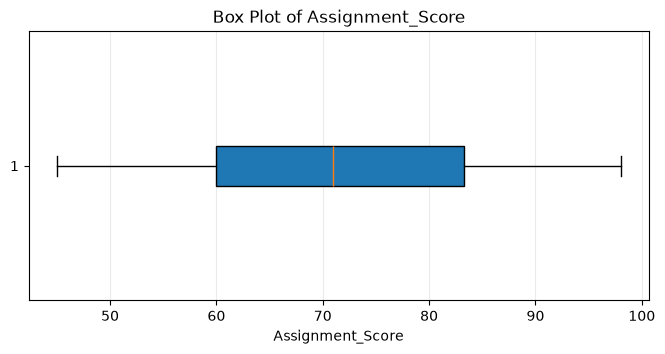

C:\Users\pmariyamma\AppData\Local\Temp\ipykernel_10752\2640557233.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


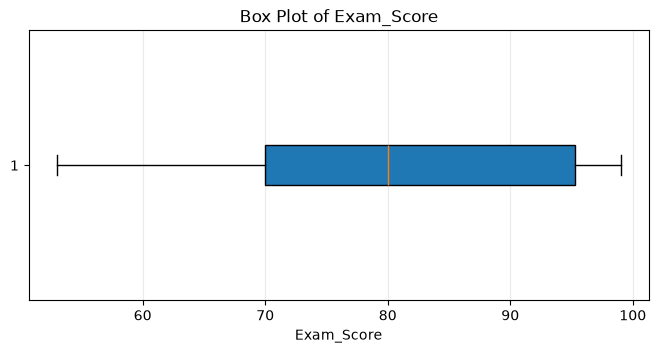

In [9]:
# Box plots for numerical columns

for col in numeric_cols:
    plt.figure(figsize=(8, 3.5))
    plt.boxplot(
        df[col],
        vert=False,
        patch_artist=True
    )
    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)
    plt.grid(axis="x", alpha=0.25)
    plt.show()


C:\Users\pmariyamma\AppData\Local\Temp\ipykernel_10752\4078948455.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(marks, vert=False,


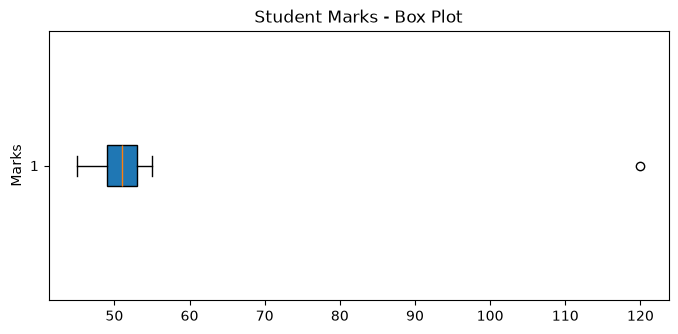

In [10]:
#box plot with outliers
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 3.5))

marks = [45, 50, 52, 48, 55, 51, 49, 53, 47, 54, 52, 50, 120]

plt.boxplot(marks, vert=False,
        patch_artist=True)
plt.ylabel("Marks")
plt.title("Student Marks - Box Plot")

plt.show()

# 11. Bar Chart — Univariate Categorical Analysis

A bar chart displays the frequency of categories.

### When to use

Use it for:
- Department
- Gender
- City
- Fee Status
- Placement Status

### Difference between histogram and bar chart

**Histogram:** numerical continuous/discrete values grouped into intervals.

**Bar chart:** categorical values.

Never confuse the two.


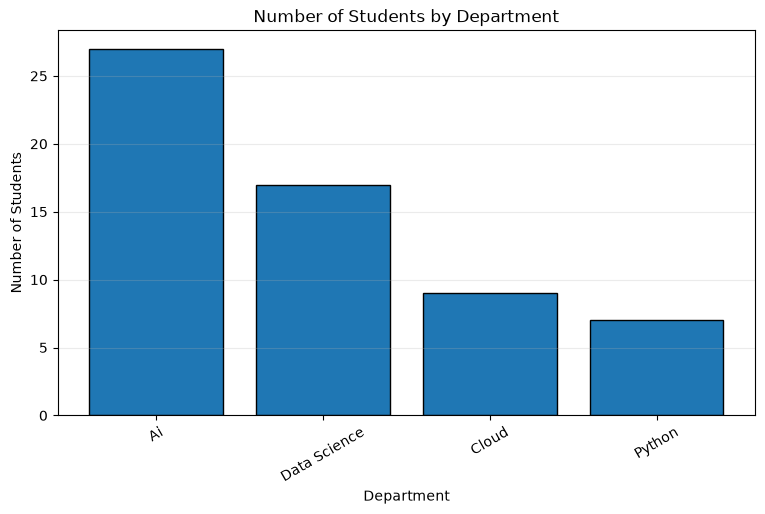

In [11]:
# Department frequency

department_counts = df["Department"].value_counts()

plt.figure(figsize=(9, 5))

plt.bar(
    department_counts.index,
    department_counts.values,
    edgecolor="black"
)

plt.title("Number of Students by Department")
plt.xlabel("Department")
plt.ylabel("Number of Students")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.25)

plt.show()


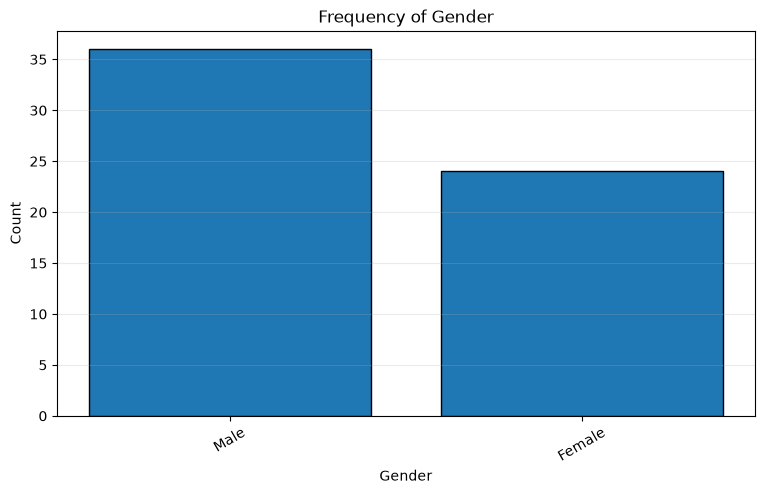

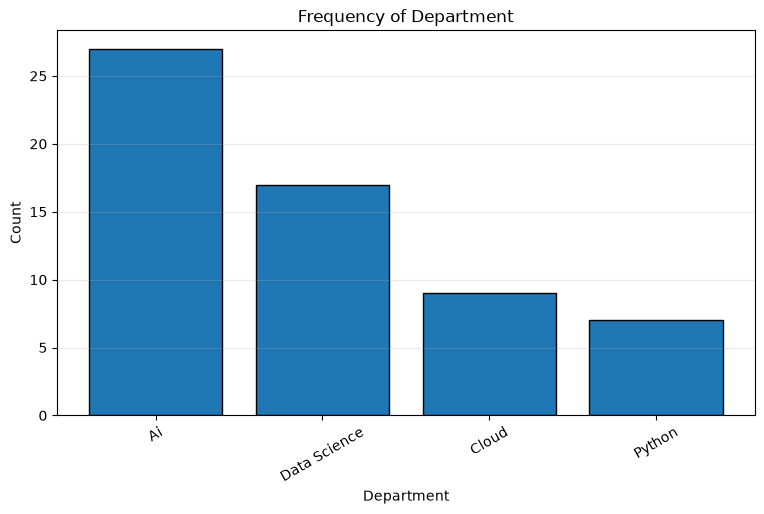

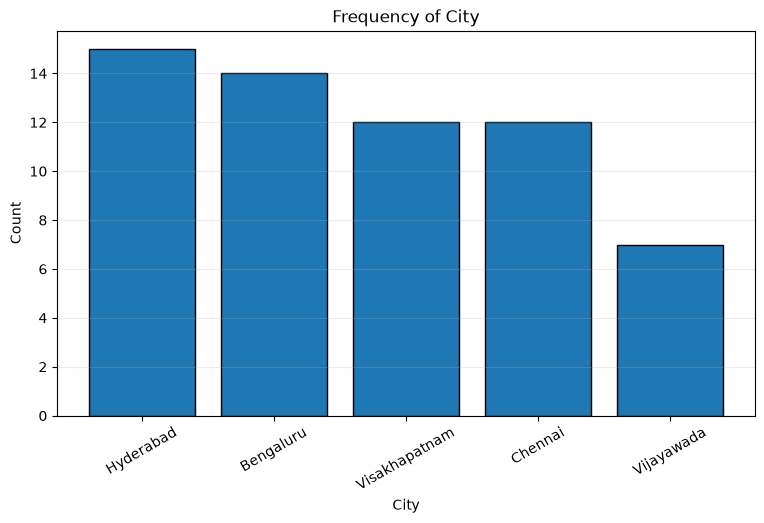

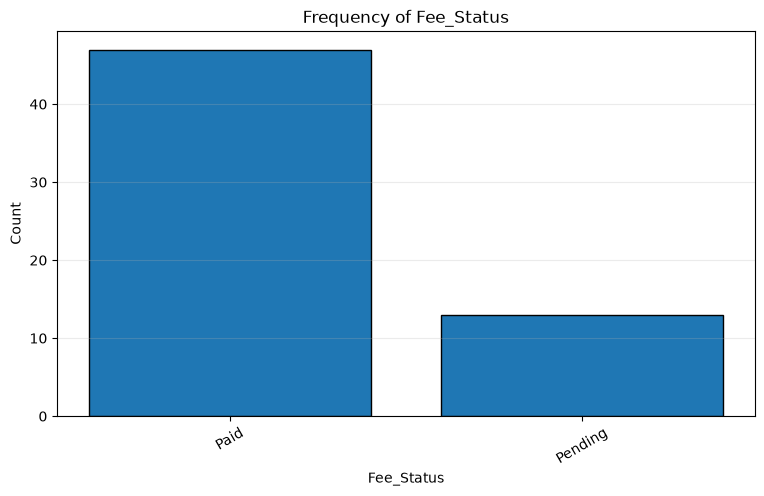

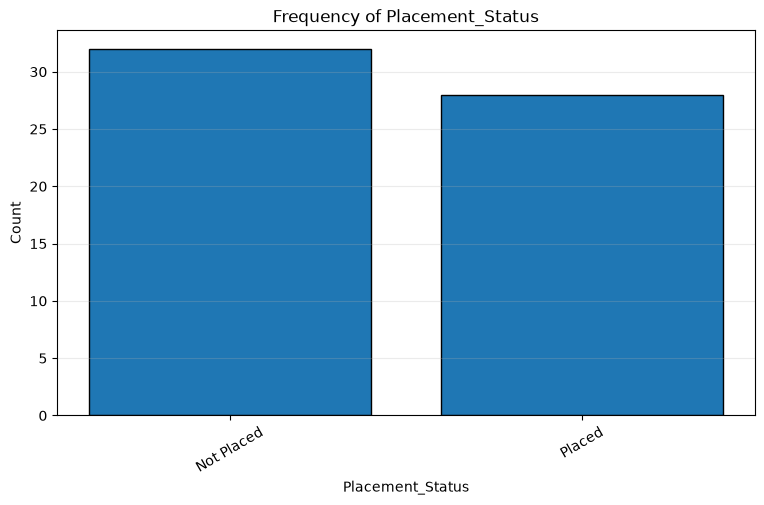

In [12]:
# Multiple categorical variables

categorical_cols = [
    "Gender",
    "Department",
    "City",
    "Fee_Status",
    "Placement_Status"
]

for col in categorical_cols:
    counts = df[col].value_counts()

    plt.figure(figsize=(9, 5))
    plt.bar(counts.index.astype(str), counts.values, edgecolor="black")
    plt.title(f"Frequency of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=30)
    plt.grid(axis="y", alpha=0.25)
    plt.show()


# 12. Pie Chart — Composition

A pie chart shows how a whole is divided among categories.

### When to use

Best when:
- number of categories is small
- the main goal is composition/percentage
- categories represent parts of one whole

Avoid pie charts when there are many categories or when exact comparison is important.

### Example

Student placement status.


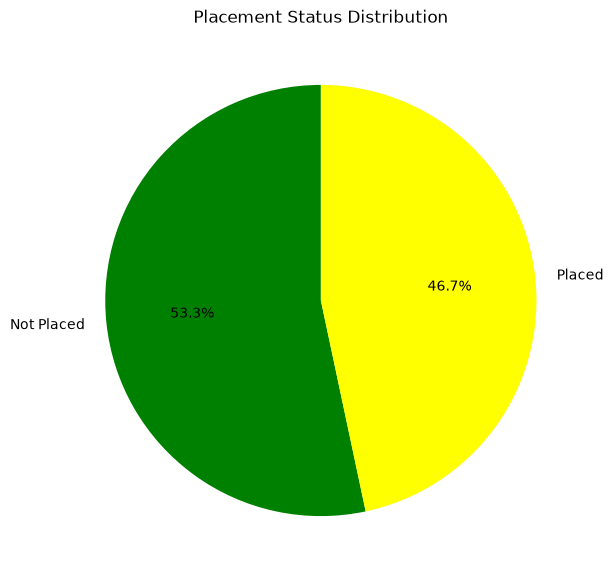

In [13]:
placement_counts = df["Placement_Status"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    placement_counts.values,
    labels=placement_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["green", "yellow"]
)

plt.title("Placement Status Distribution")
plt.show()


# 13. Stem Plot — Small Numerical Dataset

A stem plot displays individual numerical observations using stems and markers.

### When useful

- small datasets
- seeing individual observations
- discrete numerical values
- educational demonstration of distribution

It is less common than histograms for large real-world datasets.


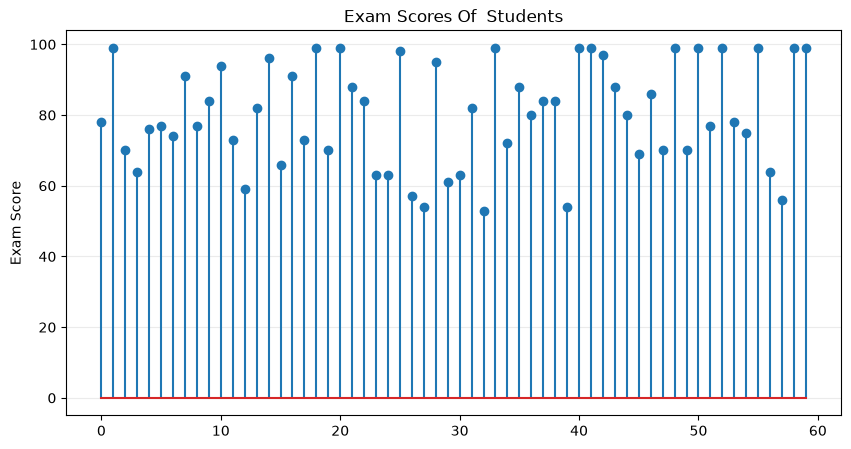

In [14]:
plt.figure(figsize=(10, 5))

plt.stem(
    df["Exam_Score"]
)

plt.title("Exam Scores Of  Students")
#plt.xlabel("Exam Score")
plt.ylabel("Exam Score")
plt.grid(axis="y", alpha=0.25)

plt.show()


# 14. BIVARIATE ANALYSIS

Bivariate analysis studies **two variables together**.

Main questions:

- Is there a relationship?
- Does one variable increase when another increases?
- Are two groups different?
- Is there a trend?
- Is the relationship linear or nonlinear?

Important Matplotlib plots:
- Scatter plot
- Line plot
- Grouped bar chart
- Area plot


# 15. Scatter Plot — Numerical vs Numerical

A scatter plot places one numerical variable on X and another on Y.

### When to use

Use it to investigate:
- relationship
- trend
- clusters -a group of data points that are similar or close to each other.
- outliers
- correlation

### ML examples

- Study Hours vs Exam Score
- Attendance vs Exam Score
- Assignment Score vs Exam Score

This is one of the most important EDA plots for ML.


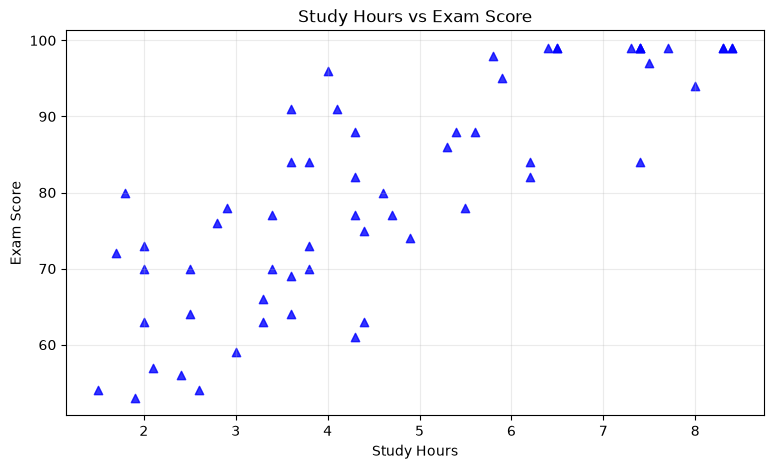

In [15]:
# Study Hours vs Exam Score

plt.figure(figsize=(9, 5))

plt.scatter(
    df["Study_Hours"],
    df["Exam_Score"],
    alpha=0.8,
    marker="^",
    color="blue"
)

plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.grid(True, alpha=0.25)

plt.show()


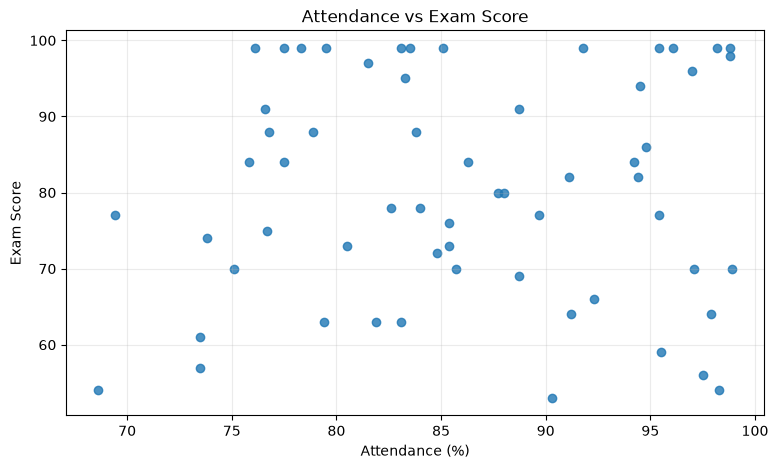

In [16]:
# Attendance vs Exam Score

plt.figure(figsize=(9, 5))

plt.scatter(
    df["Attendance"],
    df["Exam_Score"],
    alpha=0.8
)

plt.title("Attendance vs Exam Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")
plt.grid(True, alpha=0.25)

plt.show()


# 16. Line Plot — Trend / Ordered Data

Line plots connect observations and are particularly useful when the X-axis has a meaningful order.

Common uses:
- time series
- monthly trends
- training loss
- validation loss
- performance over epochs

We can use enrollment date to demonstrate a time-oriented visualization.


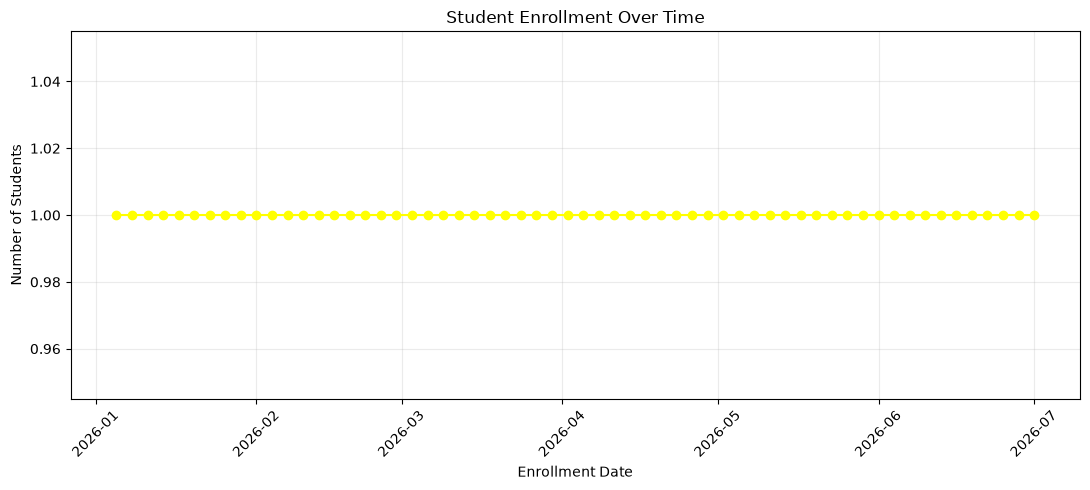

In [17]:
# Number of students enrolled over time

enrollment_counts = (
    df.groupby("Enrollment_Date")
      .size()
      .sort_index()
)

plt.figure(figsize=(11, 5))

plt.plot(
    enrollment_counts.index,
    enrollment_counts.values,
    marker="o",
    color="yellow"
)

plt.title("Student Enrollment Over Time")
plt.xlabel("Enrollment Date")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.25)
""" tight-layout
It automatically adjusts:
Space around the title
Space around X-axis and Y-axis labels
Space around tick labels
Space between multiple plots"""

plt.tight_layout()

plt.show()


# 17. Grouped Bar Chart — Categorical vs Numerical

Grouped bars are useful when comparing a numerical measure across categories and a second grouping variable.

Example:
**Average Exam Score by Department and Gender**

### When to use

- compare groups
- compare categories across another category
- analyze performance differences


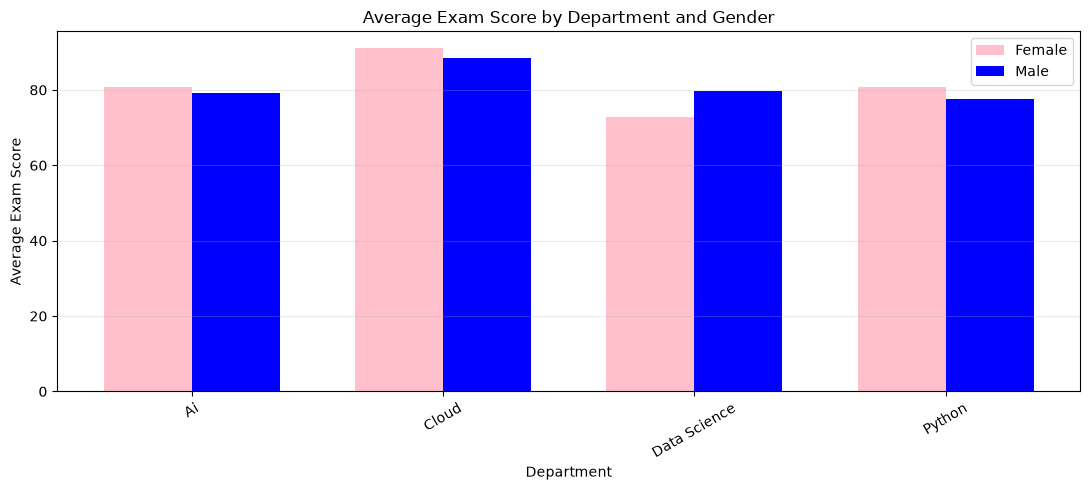

In [18]:
"""unstack-takes one level of a MultiIndex and turns it into columns."""

grouped = (
    df.groupby(["Department", "Gender"])["Exam_Score"]
      .mean()
      .unstack(fill_value=0)
)

x = np.arange(len(grouped.index))
width = 0.35

plt.figure(figsize=(11, 5))

for i, gender in enumerate(grouped.columns):
    plt.bar(
        x + (i - (len(grouped.columns) - 1) / 2) * width,
        grouped[gender],
        width,
        label=gender,
        color="blue" if gender == "Male" else "pink"
        
    )

plt.title("Average Exam Score by Department and Gender")
plt.xlabel("Department")
plt.ylabel("Average Exam Score")

plt.xticks(x, grouped.index, rotation=30)

plt.legend()
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# 18. Area Plot — Trend and Cumulative Visual Impression

An area plot is similar to a line plot but fills the area below the line.

### When useful

- trends over an ordered variable
- cumulative-looking patterns
- comparing changing quantities

For this dataset, we can visualize average exam score by sorted study hours.


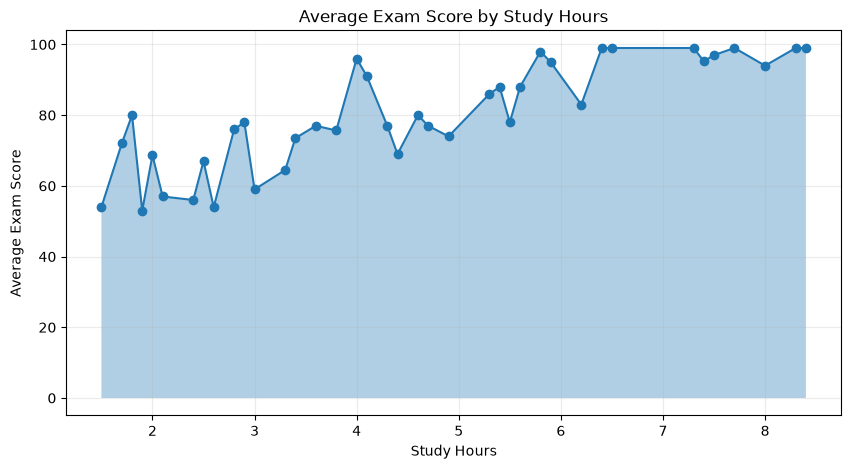

In [19]:
study_summary = (
    df.groupby("Study_Hours")["Exam_Score"]
      .mean()
      .sort_index()
)

plt.figure(figsize=(10, 5))

plt.fill_between(
    study_summary.index,
    study_summary.values,
    alpha=0.35
)

plt.plot(
    study_summary.index,
    study_summary.values,
    marker="o"
)

plt.title("Average Exam Score by Study Hours")
plt.xlabel("Study Hours")
plt.ylabel("Average Exam Score")
plt.grid(True, alpha=0.25)

plt.show()


# 19. MULTIVARIATE ANALYSIS

Multivariate analysis examines **three or more variables**.

Example:

```text
Study Hours → Exam Score
       +
Department
       +
Gender
```

Instead of looking only at Study Hours and Exam Score, we can use color/grouping to see whether the relationship changes across categories.

Important plots:
- colored scatter plot
- bubble chart
- multiple line plots
- stacked bar chart
- heatmap
- 3D scatter
- 3D surface


# 20. Colored Scatter Plot — Three Variables

A scatter plot can represent:
- X → variable 1
- Y → variable 2
- color → variable 3

Example:
- X = Study Hours
- Y = Exam Score
- Color = Gender

This is a simple and powerful multivariate visualization.


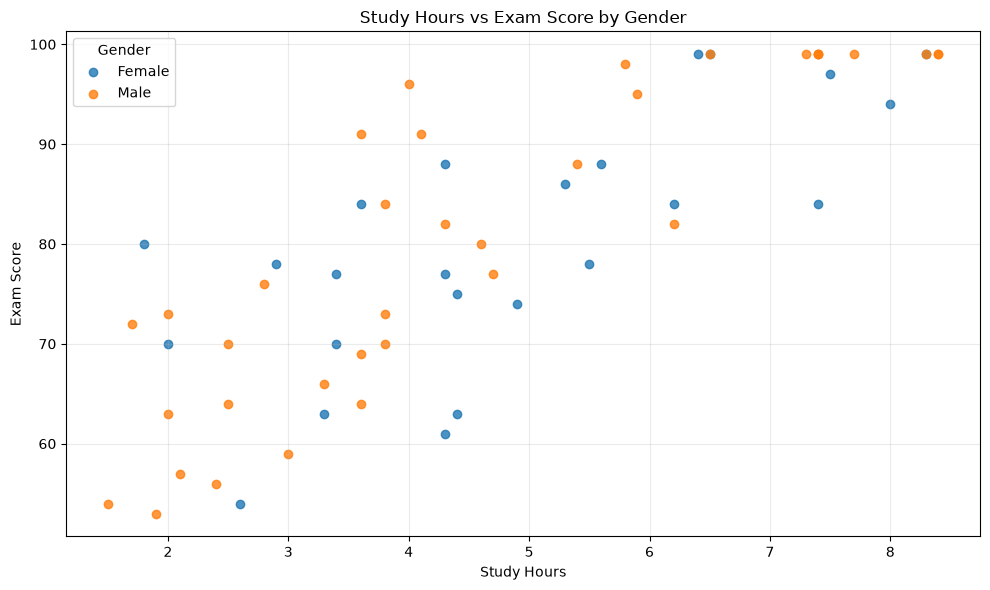

In [20]:
plt.figure(figsize=(10, 6))

for gender, group in df.groupby("Gender"):

    plt.scatter(
        group["Study_Hours"],
        group["Exam_Score"],
        label=gender,
        alpha=0.8
    )

plt.title("Study Hours vs Exam Score by Gender")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.legend(title="Gender")
plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


# 21. Bubble Chart — Four Variables

A bubble chart is essentially a scatter plot where marker size represents another variable.

Example:
- X = Attendance
- Y = Exam Score
- Bubble size = Study Hours
- Color/group = Department

### When useful

When you need to display multiple dimensions in one chart.

### Caution

Too many visual dimensions can make charts difficult to interpret. Use bubble charts only when the extra variable provides meaningful information.


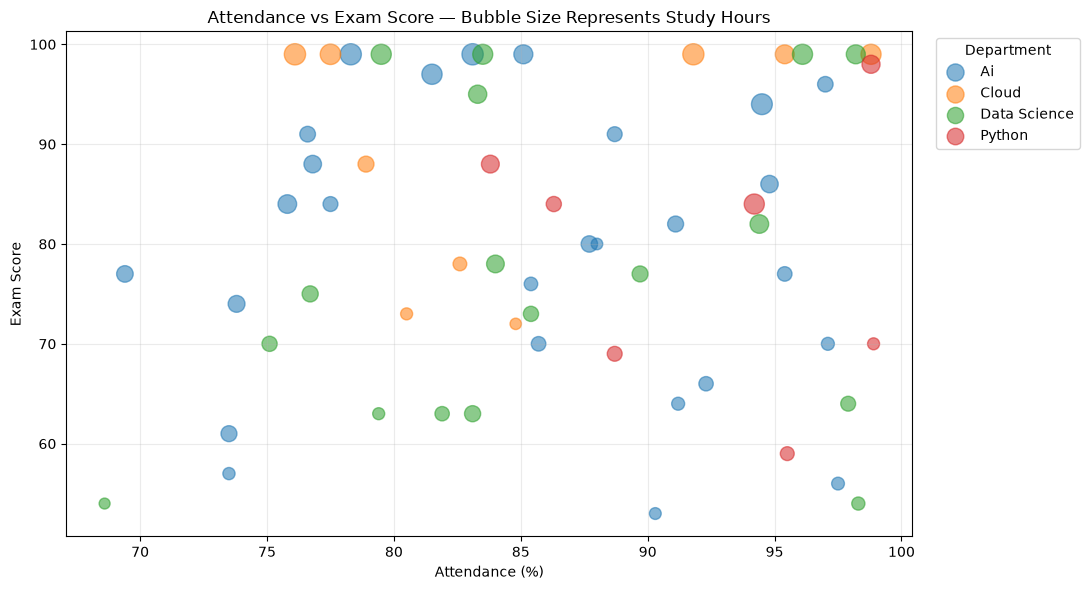

In [21]:
plt.figure(figsize=(11, 6))

for department, group in df.groupby("Department"):

    plt.scatter(
        group["Attendance"],
        group["Exam_Score"],
        s=(group["Study_Hours"] + 1) * 25,
        alpha=0.55,
        label=department
    )

plt.title("Attendance vs Exam Score — Bubble Size Represents Study Hours")

plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")

plt.legend(
    title="Department",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


# 22. Multiple Line Plot

Multiple line plots allow comparison of several related numerical variables.

Here we compare:
- Attendance
- Assignment Score
- Exam Score

Because the variables have different meanings and scales, this visualization should be interpreted carefully. It is mainly useful for teaching comparison and pattern recognition.


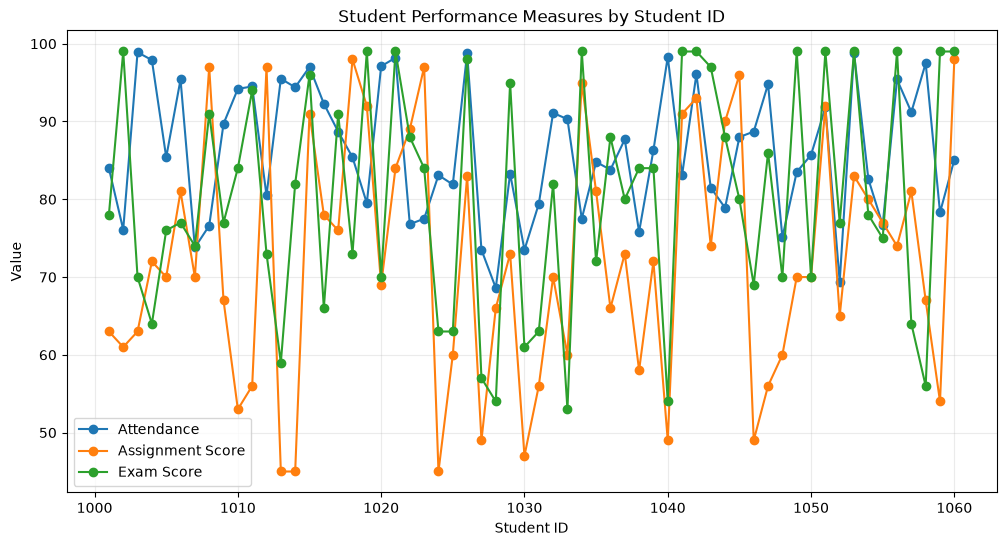

In [22]:
# Sort by Student_ID so the lines follow a stable student order
plot_df = df.sort_values("Student_ID")

plt.figure(figsize=(12, 6))

plt.plot(
    plot_df["Student_ID"],
    plot_df["Attendance"],
    marker="o",
    label="Attendance"
)

plt.plot(
    plot_df["Student_ID"],
    plot_df["Assignment_Score"],
    marker="o",
    label="Assignment Score"
)

plt.plot(
    plot_df["Student_ID"],
    plot_df["Exam_Score"],
    marker="o",
    label="Exam Score"
)

plt.title("Student Performance Measures by Student ID")
plt.xlabel("Student ID")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.25)

plt.show()


# 23. Stacked Bar Chart — Composition Across Groups

A stacked bar chart shows how multiple components contribute to each category.

Example:
- Department
- Placement Status

This helps answer:

> How is placement status distributed within each department?

It is especially useful for composition comparisons.


<Figure size 1100x600 with 0 Axes>

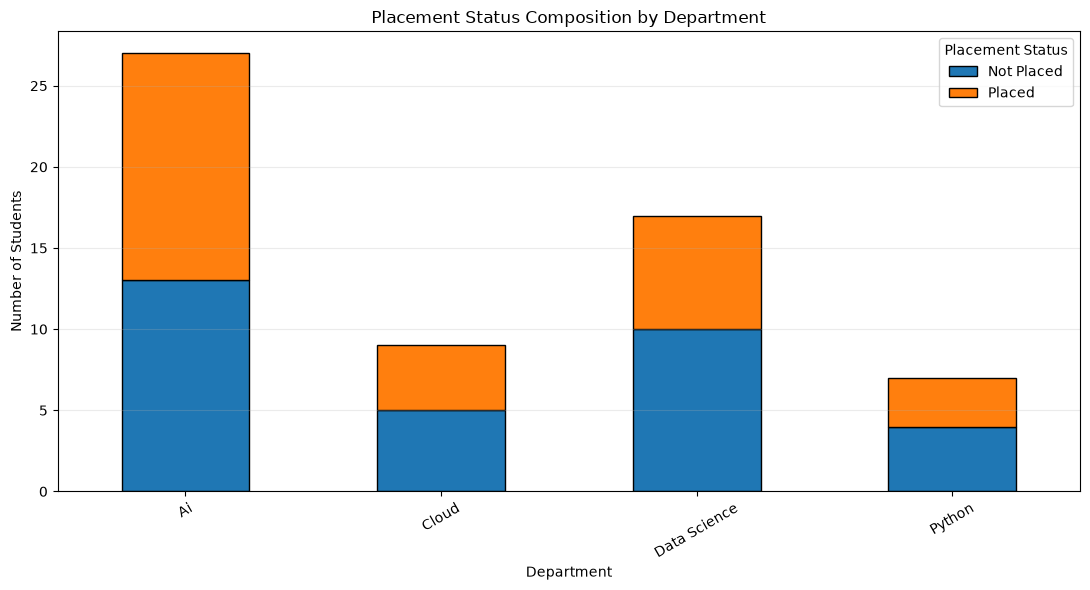

In [23]:
#crosstab-Count how many combinations of two categories exist
placement_by_dept = pd.crosstab(
    df["Department"],
    df["Placement_Status"]
)

plt.figure(figsize=(11, 6))

placement_by_dept.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    edgecolor="black"
)

plt.title("Placement Status Composition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Students")

plt.xticks(rotation=30)

plt.legend(title="Placement Status")

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# 24. Correlation Analysis — Matplotlib Heatmap

Correlation measures the strength and direction of a linear relationship between numerical variables.

Typical range:

```text
+1  → strong positive relationship
 0  → no linear relationship
-1  → strong negative relationship
```

### Important

Correlation does **not** prove causation.

Matplotlib does not provide a dedicated high-level statistical heatmap function like Seaborn, but we can create one using `imshow()`.

This is a valuable foundation before learning Seaborn.


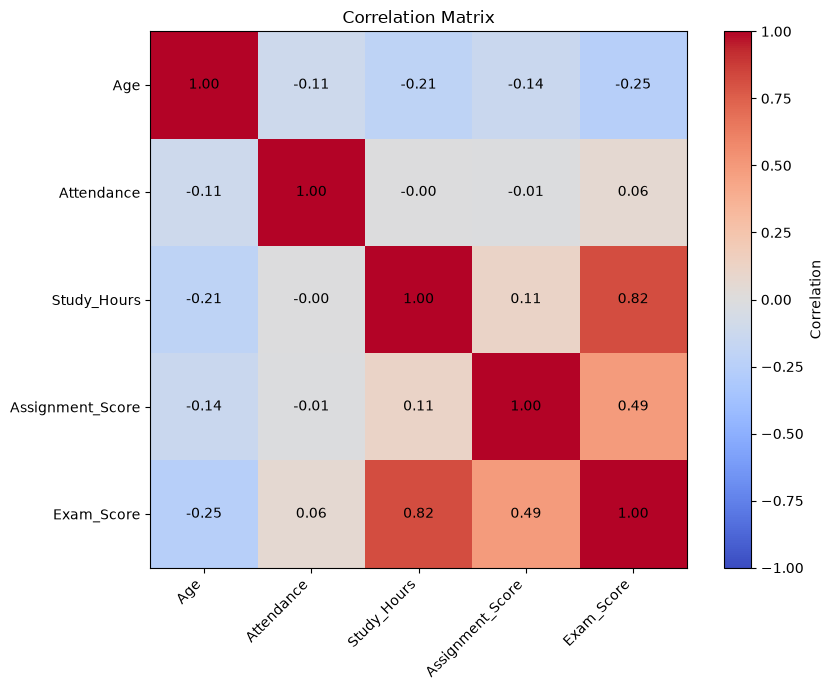

In [24]:
corr_cols = [
    "Age",
    "Attendance",
    "Study_Hours",
    "Assignment_Score",
    "Exam_Score"
]

corr = df[corr_cols].corr()

plt.figure(figsize=(9, 7))

image = plt.imshow(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Correlation Matrix")

# Add correlation values
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(
            j,
            i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(image, label="Correlation")

plt.tight_layout()
plt.show()

# 25. 3D Scatter Plot — Three Numerical Variables

3D plots can display three numerical dimensions:

- X = Study Hours
- Y = Attendance
- Z = Exam Score

### When useful

- teaching
- exploring three-dimensional relationships
- engineering/scientific data

### Caution

3D charts can be difficult to read from a static image. For most ML EDA, a well-designed 2D chart is often easier to interpret.


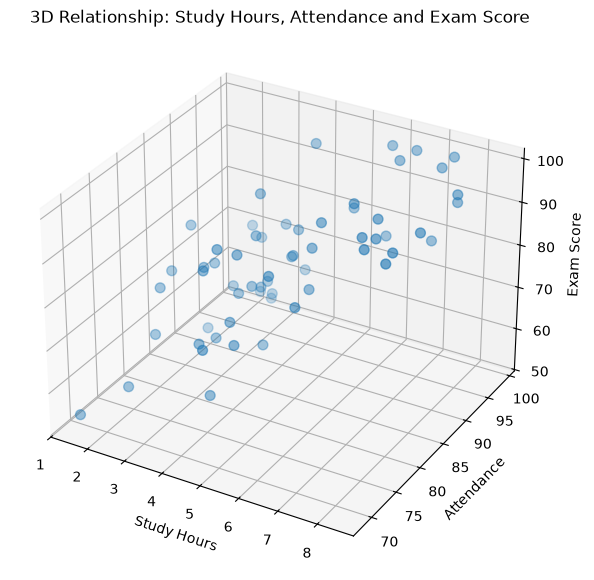

In [25]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))
# row,column,plot
ax = fig.add_subplot(111, projection="3d") 

#s=It controls how large each dot/bubble appears.

ax.scatter(
    df["Study_Hours"],
    df["Attendance"],
    df["Exam_Score"],
    s=50,
    alpha=0.8
)

ax.set_title("3D Relationship: Study Hours, Attendance and Exam Score")
ax.set_xlabel("Study Hours")
ax.set_ylabel("Attendance")
ax.set_zlabel("Exam Score")

plt.show()


# 26. 3D Surface Plot

A surface plot represents a numerical surface over two input dimensions.

For this student dataset, we can demonstrate a smooth surface based on interpolation-like grid construction from the observed Study Hours and Attendance relationship.

### Important teaching point

A surface plot can suggest a trend, but it is **not the same thing as a trained ML model**. We should not interpret the surface as a prediction model unless we actually fit a model.


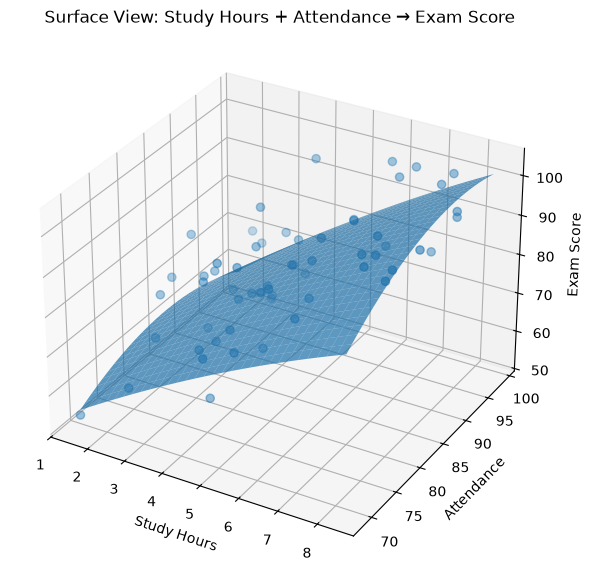

In [26]:
# Demonstration surface based on a simple polynomial trend fitted to the observed data.
# This is for visualization/teaching, not an ML prediction model.

x = df["Study_Hours"].to_numpy()
y = df["Attendance"].to_numpy()
z = df["Exam_Score"].to_numpy()

# Fit a simple quadratic surface:
# z = b0 + b1*x + b2*y + b3*x^2 + b4*y^2 + b5*x*y
X = np.column_stack([
    np.ones(len(df)),
    x,
    y,
    x**2,
    y**2,
    x*y
])

coef, *_ = np.linalg.lstsq(X, z, rcond=None)

x_grid = np.linspace(x.min(), x.max(), 30)
y_grid = np.linspace(y.min(), y.max(), 30)

Xg, Yg = np.meshgrid(x_grid, y_grid)

Zg = (
    coef[0]
    + coef[1] * Xg
    + coef[2] * Yg
    + coef[3] * Xg**2
    + coef[4] * Yg**2
    + coef[5] * Xg * Yg
)

fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    Xg,
    Yg,
    Zg,
    alpha=0.7
)

ax.scatter(
    x,
    y,
    z,
    s=35,
    alpha=0.8
)

ax.set_title("Surface View: Study Hours + Attendance → Exam Score")
ax.set_xlabel("Study Hours")
ax.set_ylabel("Attendance")
ax.set_zlabel("Exam Score")

plt.show()


# 27. Error Bar Plot

Error bars communicate uncertainty or variability around a value.

In real ML/data-science projects, they can be useful for:
- mean ± standard deviation
- confidence intervals
- experimental results
- model performance comparisons

We can demonstrate average Exam Score by Department with standard deviation.


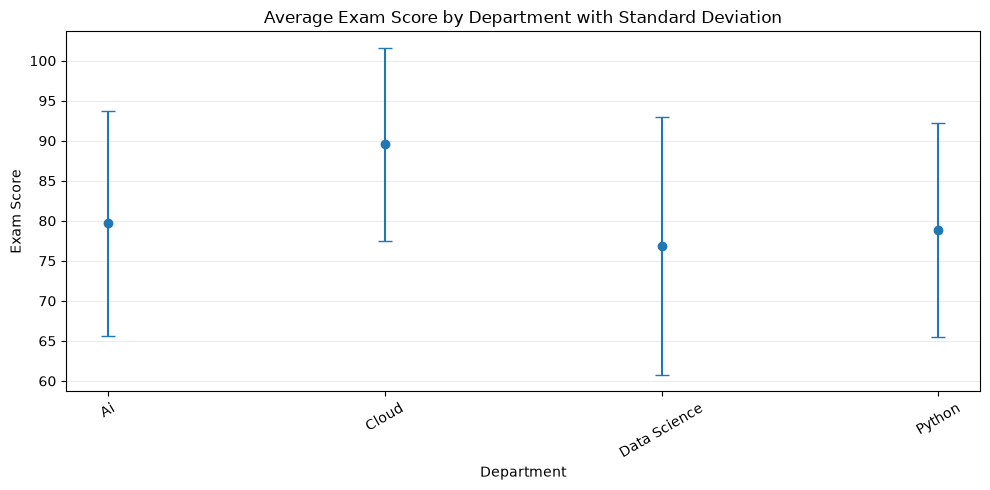

In [27]:
stats = (
    df.groupby("Department")["Exam_Score"]
      .agg(["mean", "std"])
      .fillna(0)
)

plt.figure(figsize=(10, 5))

plt.errorbar(
    stats.index,
    stats["mean"],
    yerr=stats["std"],
    fmt="o",
    capsize=5
)

plt.title("Average Exam Score by Department with Standard Deviation")
plt.xlabel("Department")
plt.ylabel("Exam Score")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# 28. Subplots — Multiple Views in One Figure

Subplots are useful when multiple related visualizations need to be compared.

Example:
- Exam Score distribution
- Attendance distribution
- Study Hours distribution
- Assignment Score distribution

This is useful for dashboards and reports.


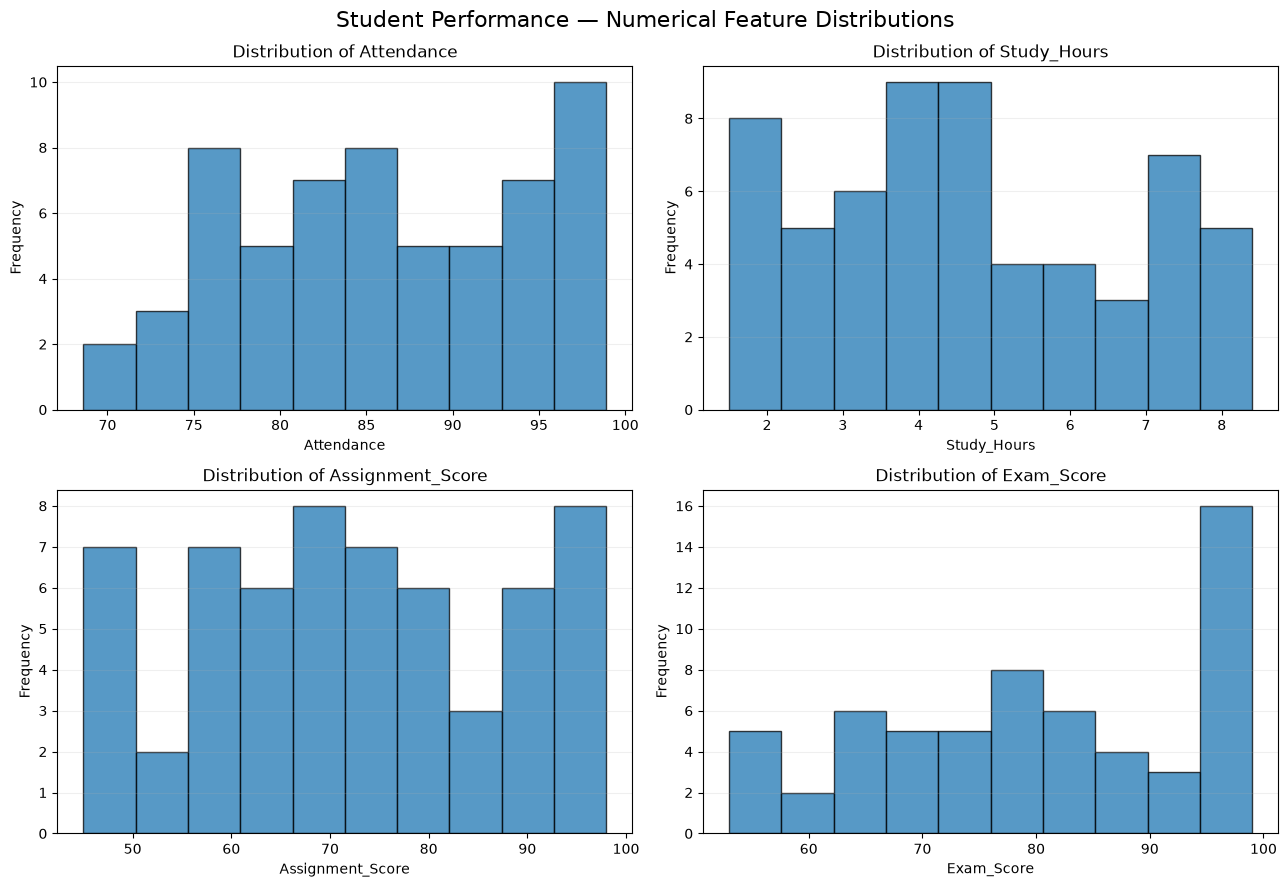

In [28]:
"""┌─────────────┬─────────────┐
│   Plot 1    │   Plot 2    │
│   axes[0,0] │   axes[0,1] │
├─────────────┼─────────────┤
│   Plot 3    │   Plot 4    │
│   axes[1,0] │   axes[1,1] │
└─────────────┴─────────────┘"""

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

plot_columns = [
    "Attendance",
    "Study_Hours",
    "Assignment_Score",
    "Exam_Score"
]

for ax, col in zip(axes.ravel(), plot_columns):
    ax.hist(
        df[col],
        bins=10,
        edgecolor="black",
        alpha=0.75
    )
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.2)

plt.suptitle("Student Performance — Numerical Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()


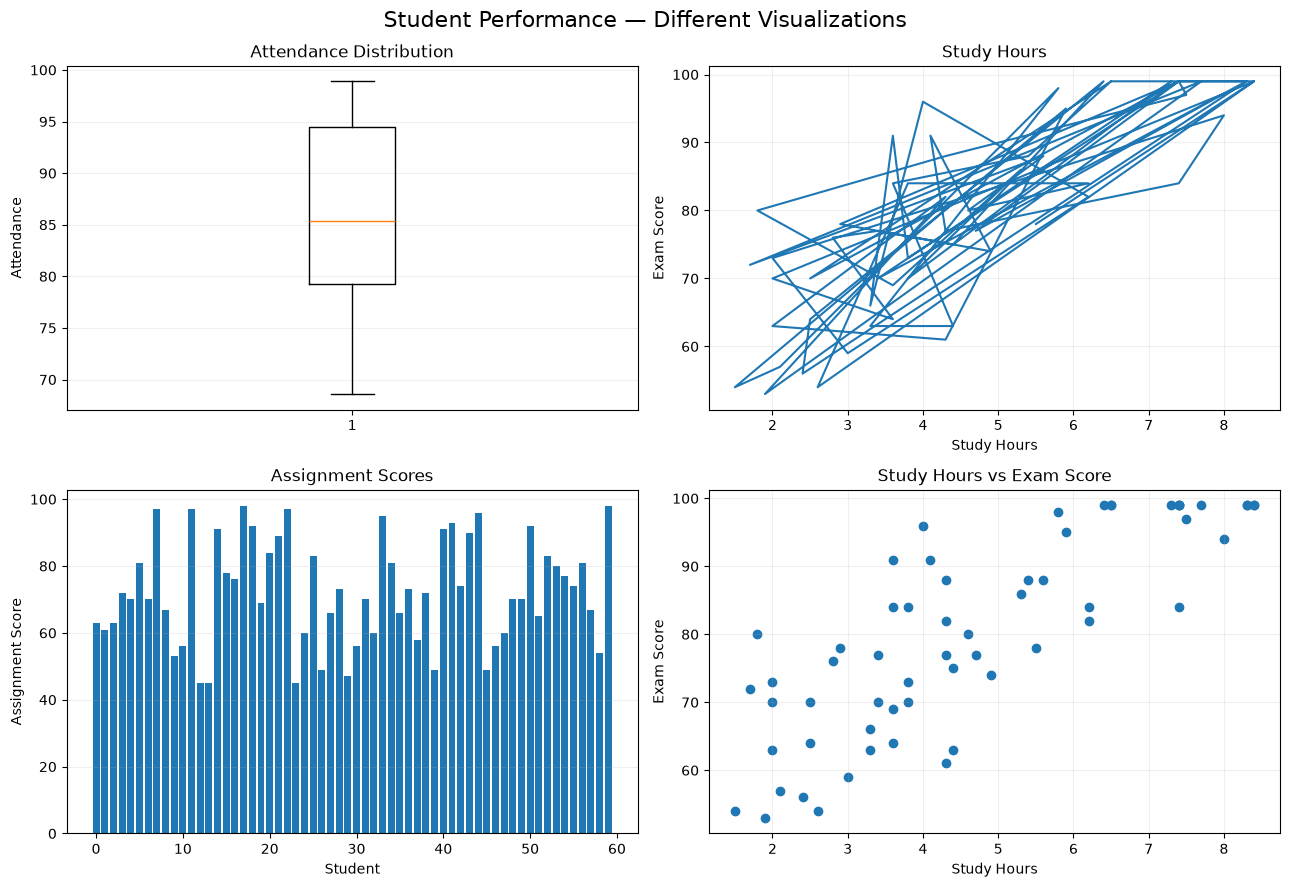

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Attendance - Box Plot
axes[0, 0].boxplot(df["Attendance"].dropna())

axes[0, 0].set_title("Attendance Distribution")
axes[0, 0].set_ylabel("Attendance")
axes[0, 0].grid(axis="y", alpha=0.2)


# 2. Study Hours - Line Plot
axes[0, 1].plot(df["Study_Hours"], df["Exam_Score"])

axes[0, 1].set_title("Study Hours")
axes[0, 1].set_xlabel("Study Hours")
axes[0, 1].set_ylabel("Exam Score")
axes[0, 1].grid(alpha=0.2)


# 3. Assignment Score - Bar Plot
axes[1, 0].bar(
    range(len(df)),
    df["Assignment_Score"]
)

axes[1, 0].set_title("Assignment Scores")
axes[1, 0].set_xlabel("Student")
axes[1, 0].set_ylabel("Assignment Score")
axes[1, 0].grid(axis="y", alpha=0.2)


# 4. Exam Score - Scatter Plot
axes[1, 1].scatter(
    df["Study_Hours"],
    df["Exam_Score"]
)

axes[1, 1].set_title("Study Hours vs Exam Score")
axes[1, 1].set_xlabel("Study Hours")
axes[1, 1].set_ylabel("Exam Score")
axes[1, 1].grid(alpha=0.2)


plt.suptitle(
    "Student Performance — Different Visualizations",
    fontsize=16
)

plt.tight_layout()
plt.show()

# 29. Annotation

Annotations help explain an important observation directly on a graph.

Examples:
- highest score
- lowest score
- unusual point
- important business event

Here we annotate the student with the highest exam score.


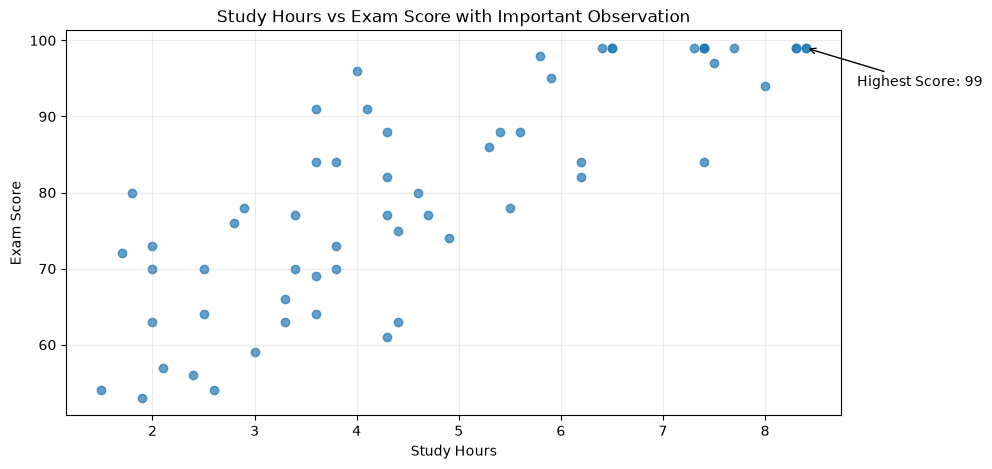

In [30]:
max_idx = df["Exam_Score"].idxmax()
max_student = df.loc[max_idx]

plt.figure(figsize=(10, 5))

plt.scatter(
    df["Study_Hours"],
    df["Exam_Score"],
    alpha=0.7
)

plt.annotate(
    f"Highest Score: {max_student['Exam_Score']}",
    xy=(max_student["Study_Hours"], max_student["Exam_Score"]),
    xytext=(max_student["Study_Hours"] + 0.5, max_student["Exam_Score"] - 5),
    arrowprops=dict(arrowstyle="->")
)

plt.title("Study Hours vs Exam Score with Important Observation")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.grid(True, alpha=0.25)

plt.show()


# Plot Classification by Number of Variables

Plots can also be classified according to the number of variables being analyzed.

| Analysis Type | Number of Variables | Analytical Purpose | Common Plots | Example |
|---|---:|---|---|---|
| **Univariate Analysis** | 1 | Understand the distribution, frequency, spread, and characteristics of a single variable | Histogram, Bar Plot, Pie Chart, Box Plot, Violin Plot, ECDF Plot, Stem Plot | Distribution of Exam Scores |
| **Bivariate Analysis** | 2 | Analyze the relationship, comparison, or association between two variables | Scatter Plot, Line Plot, Bar Plot, Box Plot, 2D Histogram, Hexbin Plot, Contour Plot | Study Hours vs Exam Score |
| **Multivariate Analysis** | 3 or more | Analyze interactions, relationships, patterns, or comparisons involving multiple variables | Grouped Bar Plot, Stacked Bar Plot, Stack Plot, Contour Plot, Pseudocolor Plot, Quiver Plot, Streamplot | Study Hours + Attendance + Assignment Score + Exam Score |


# Quick Plot Selection Guide

The appropriate plot depends on the type of data, the number of variables, and the analytical objective.

| Analytical Objective | Recommended Plot | Purpose / Explanation |
|---|---|---|
| Analyze the distribution of a numerical variable | **Histogram** | Displays the frequency distribution of numerical values using intervals called bins. |
| Identify outliers and understand data spread | **Box Plot** | Displays minimum, first quartile, median, third quartile, maximum, and potential outliers. |
| Analyze the relationship between two numerical variables | **Scatter Plot** | Displays individual observations as points to identify relationships, trends, clusters, and possible correlations. |
| Compare values across different categories | **Bar Plot** | Represents categorical values using rectangular bars, making category comparisons easy. |
| Compare categories containing long names | **Horizontal Bar Plot** | Displays bars horizontally, providing more space for long category labels. |
| Analyze trends or changes across an ordered sequence or time | **Line Plot** | Connects observations with lines to show trends, increases, decreases, and fluctuations. |
| Display the proportion of categories | **Pie Chart** | Divides a circle into sectors to represent the relative proportion of each category. |
| Compare the distribution of a numerical variable across groups | **Box Plot** | Allows comparison of median, spread, and outliers between different categories or groups. |
| Analyze the detailed shape of distributions across groups | **Violin Plot** | Combines summary statistics with an estimated distribution shape to compare groups. |
| Display the magnitude of values and their changes | **Area Plot** | Uses filled regions below lines to emphasize magnitude and trends. |
| Compare multiple values across categories | **Grouped Bar Plot** | Places multiple bars side by side for each category to compare several variables. |
| Compare category totals and their individual components | **Stacked Bar Plot** | Divides each bar into segments to show both total values and component contributions. |
| Analyze cumulative contributions of multiple variables over an ordered sequence | **Stack Plot** | Stacks multiple datasets to show how individual components contribute to the total. |
| Display uncertainty or variability around measurements | **Error Bar Plot** | Adds error ranges to values to represent uncertainty, variation, confidence intervals, or standard deviation. |
| Display individual observations in a discrete sequence | **Stem Plot** | Represents observations using vertical stems and markers, useful for discrete numerical data. |
| Display values that change at specific points | **Step Plot** | Represents changes using horizontal and vertical steps, suitable for discrete or event-based data. |
| Analyze very large datasets containing overlapping points | **Hexbin Plot** | Groups observations into hexagonal regions and represents point density using color intensity. |
| Analyze the joint distribution of two numerical variables | **2D Histogram** | Divides two numerical dimensions into bins and displays the number of observations in each region. |
| Analyze relationships in very dense two-dimensional data | **Hexbin Plot** | Reduces overplotting by grouping nearby observations into hexagonal bins. |
| Display equal-value regions of a numerical surface | **Contour Plot** | Uses contour lines to connect locations having similar numerical values. |
| Display numerical values in a matrix or image format | **Image Plot (`imshow`)** | Represents matrix values using colors and is commonly used for images and pixel-level data. |
| Display matrix or grid values using colored regions | **Pseudocolor Plot** | Represents numerical values using colored cells or polygons. |
| Analyze directional data using angles and distances | **Polar Plot** | Uses angular and radial coordinates instead of conventional X and Y coordinates. |
| Display direction and magnitude of vector data | **Quiver Plot** | Uses arrows to represent the direction and magnitude of vectors. |
| Visualize continuous vector-field flow | **Streamplot** | Displays streamlines to represent the direction and movement of a vector field. |
| Display the occurrence of individual events | **Event Plot** | Shows the positions of events along an axis, useful for event or activity analysis. |
| Display multiple time intervals or schedules | **Broken Bar Plot** | Represents intervals along an axis and is useful for schedules, timelines, and activity periods. |
| Analyze cumulative or proportional changes across an ordered sequence | **Stacked Area Plot** | Uses stacked filled regions to show how multiple components contribute to a total over time. |
| Analyze cumulative distribution of numerical observations | **ECDF Plot** | Shows the proportion of observations that are less than or equal to each numerical value. |

figsize   → How big is my graph?

marker    → How do individual points look?

linestyle → How does my line look?

linewidth → How thick is my line?

alpha     → How transparent is my graph element?

label     → What is the name of my data?

color     → What color should my data use?

edgecolor → What color should the border have?

bins      → How should histogram data be grouped?

rotation  → How should my labels be rotated?

grid()    → Should I show reference lines?

legend()  → How do I explain different data series? -legend is used to explain what each line, bar, or group in a chart represents.

xlim()    → What X-axis range should I display?

ylim()    → What Y-axis range should I display?



| Parameter   | Meaning                          | Common Plot           |
| ----------- | -------------------------------- | --------------------- |
| `figsize`   | Controls graph width and height  | All plots             |
| `marker`    | Shape of individual data points  | Line / Scatter        |
| `linestyle` | Style of connecting line         | Line                  |
| `linewidth` | Thickness of line                | Line                  |
| `alpha`     | Transparency / opacity           | Scatter / Line / Area |
| `label`     | Gives a name to data             | All plots             |
| `color`     | Controls graphical element color | All plots             |
| `edgecolor` | Controls border/outline color    | Bar / Histogram       |
| `bins`      | Number of histogram intervals    | Histogram             |
| `rotation`  | Rotates axis labels              | Bar / Category plots  |
| `grid()`    | Adds reference lines             | Most numerical plots  |
| `legend()`  | Displays data-series names       | Multiple datasets     |
| `xlim()`    | Controls X-axis range            | Numerical plots       |
| `ylim()`    | Controls Y-axis range            | Numerical plots       |


| Marker | Meaning  |
| ------ | -------- |
| `"o"`  | Circle   |
| `"s"`  | Square   |
| `"^"`  | Triangle |
| `"D"`  | Diamond  |
| `"*"`  | Star     |
| `"+"`  | Plus     |
| `"x"`  | X        |


| Lin style  | Meaning       |
| ------ | ------------- |
| `"-"`  | Solid line    |
| `"--"` | Dashed line   |
| `":"`  | Dotted line   |
| `"-."` | Dash-dot line |



### Definition

`ax.plot()` draws a line plot. Common customisations:

| Parameter | Meaning |
|---|---|
| `color` | line colour (name, hex, or shorthand like `"r"`) |
| `linestyle` | `"-"`, `"--"`, `"-."`, `":"` |
| `linewidth` | thickness |
| `marker` | point marker: `"o"`, `"s"`, `"^"`, `"x"` |
| `label` | name used in the legend |

Other Axes methods you'll use constantly: `set_title`, `set_xlabel`, `set_ylabel`, `legend`, `grid`, `set_xlim` / `set_ylim`, `set_xticks`, `set_yscale`.

Dataset loaded successfully.
Shape: (60, 13)


,Student_ID,Name,Age,Gender,Department,Attendance,Study_Hours,Assignment_Score,Exam_Score,City,Enrollment_Date,Fee_Status,Placement_Status
0,1001,Ravi,21,Female,Data Science,84.0,5.5,63,78,Visakhapatnam,2026-01-05,Paid,Placed
1,1002,Priya,23,Male,Cloud,76.1,8.4,61,99,Chennai,2026-01-08,Paid,Placed
2,1003,Arun,23,Female,Python,98.9,2.0,63,70,Hyderabad,2026-01-11,Paid,Placed
3,1004,Meena,21,Male,Data Science,97.9,3.6,72,64,Visakhapatnam,2026-01-14,Paid,Not Placed
4,1005,Kiran,22,Male,Ai,85.4,2.8,70,76,Vijayawada,2026-01-17,Paid,Placed


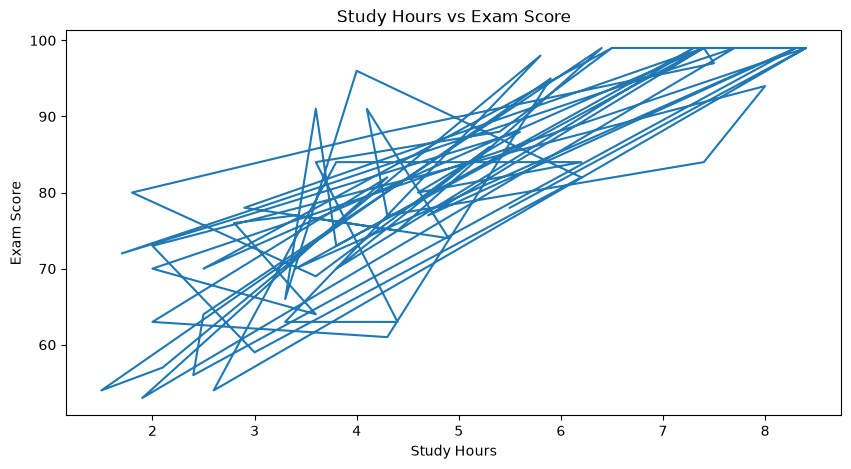

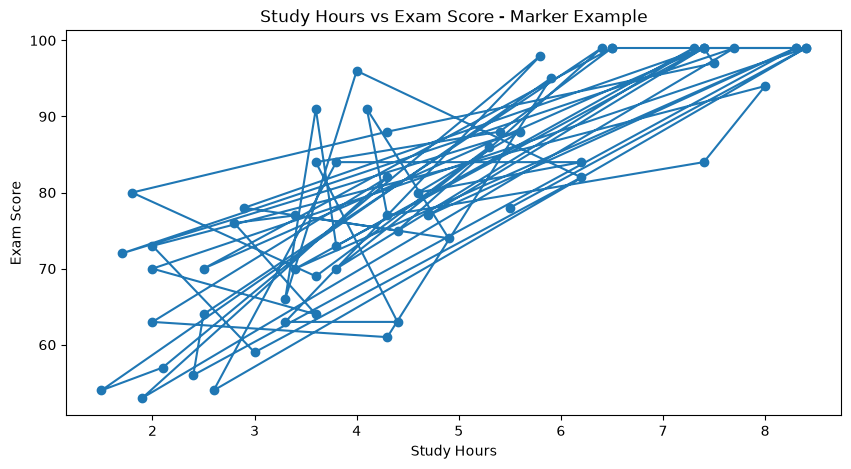

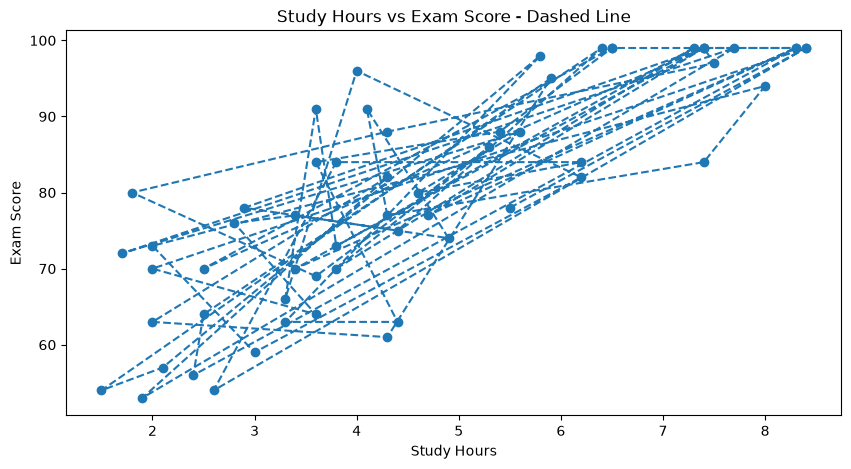

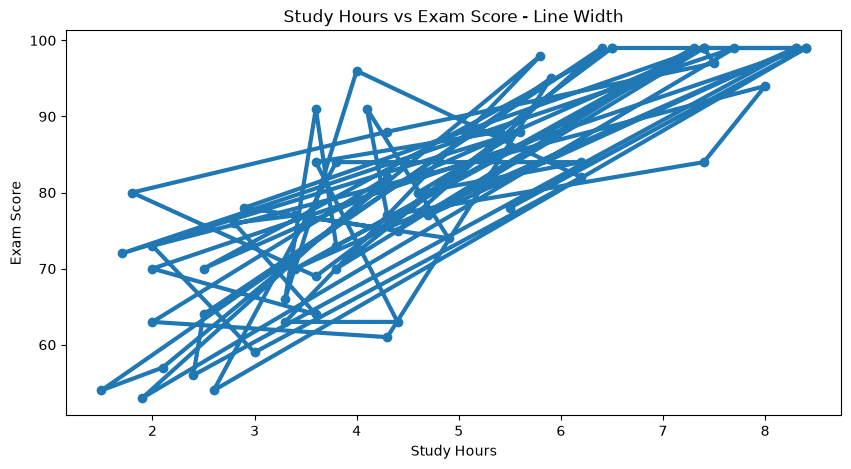

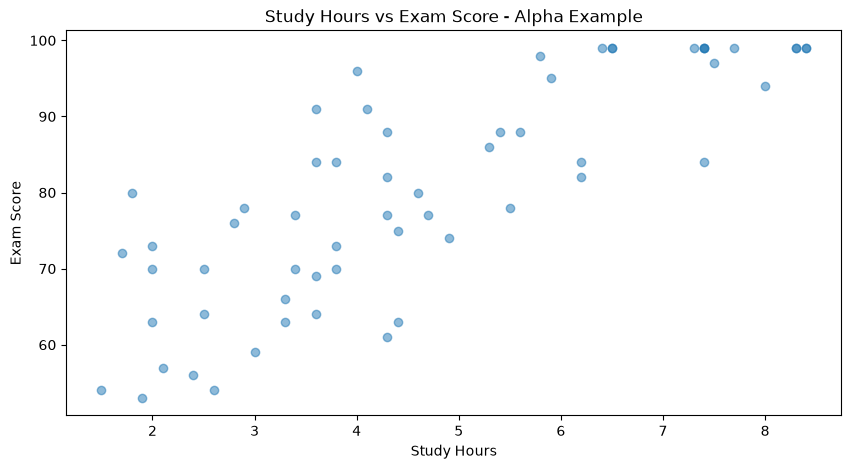

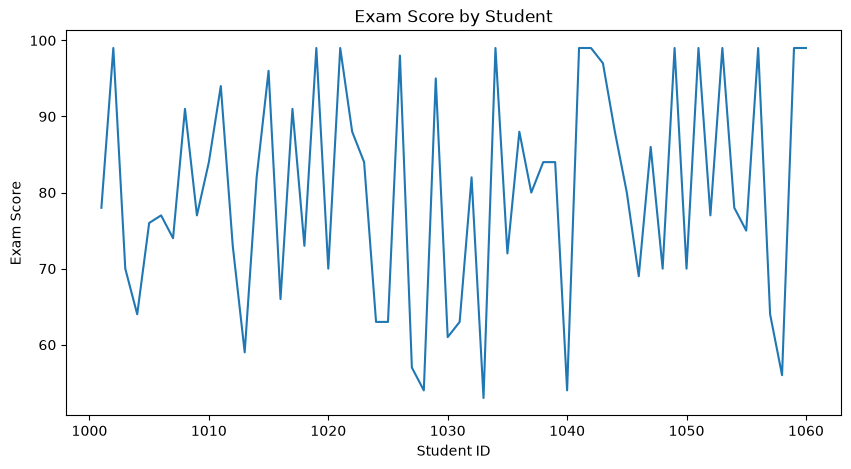

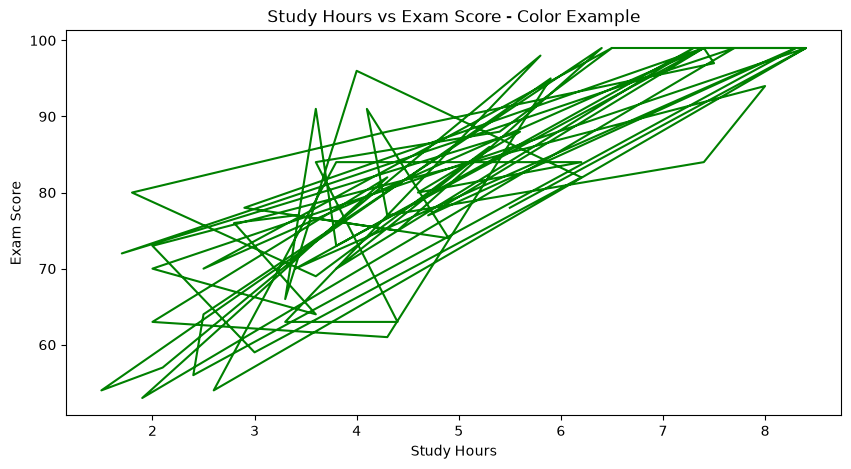

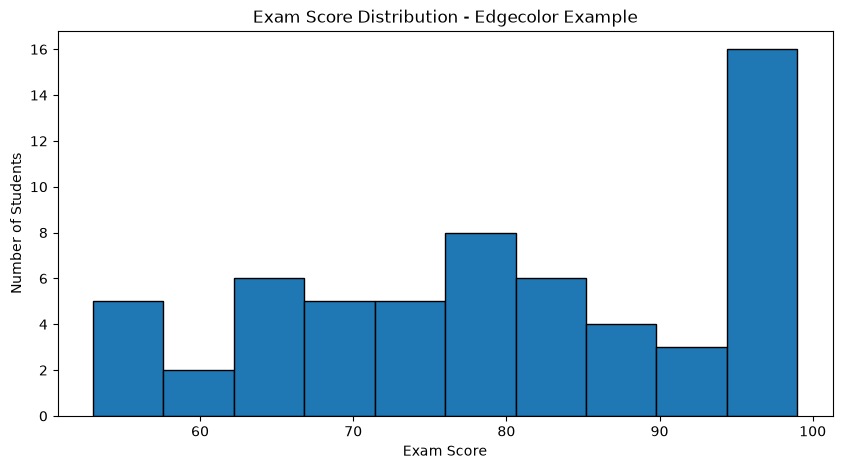

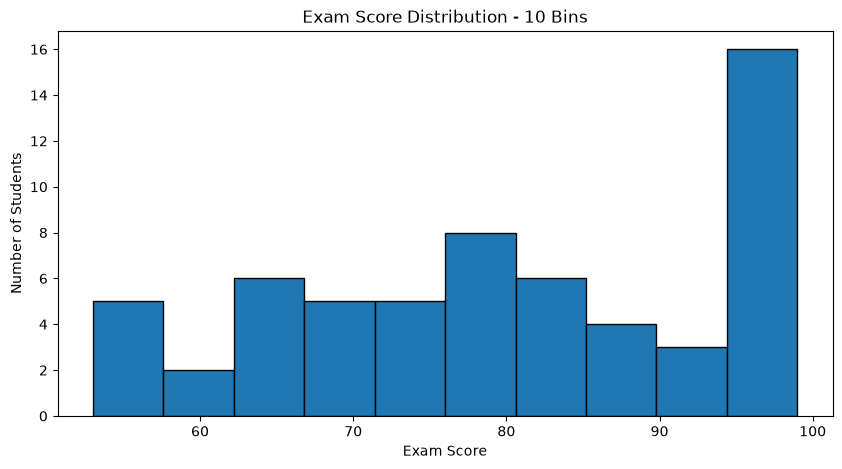

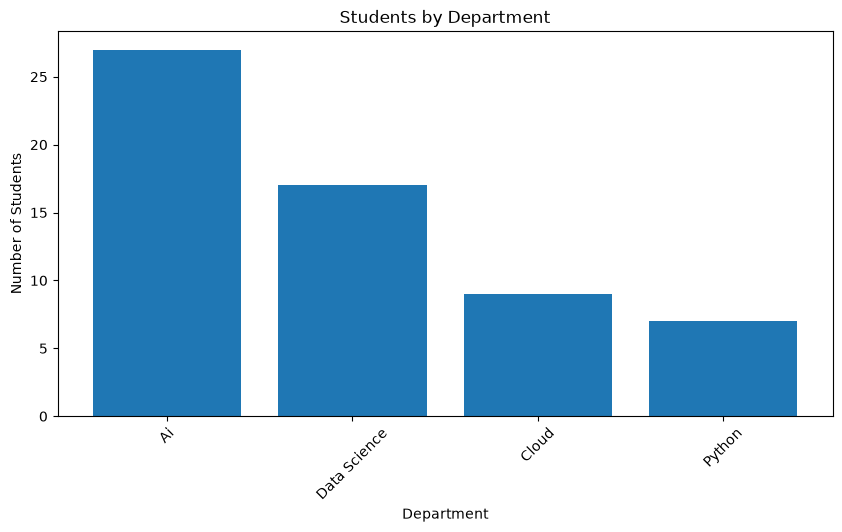

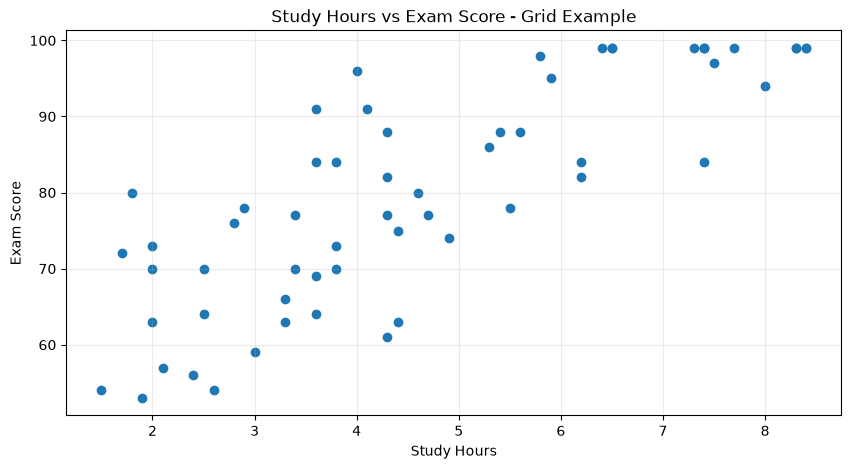

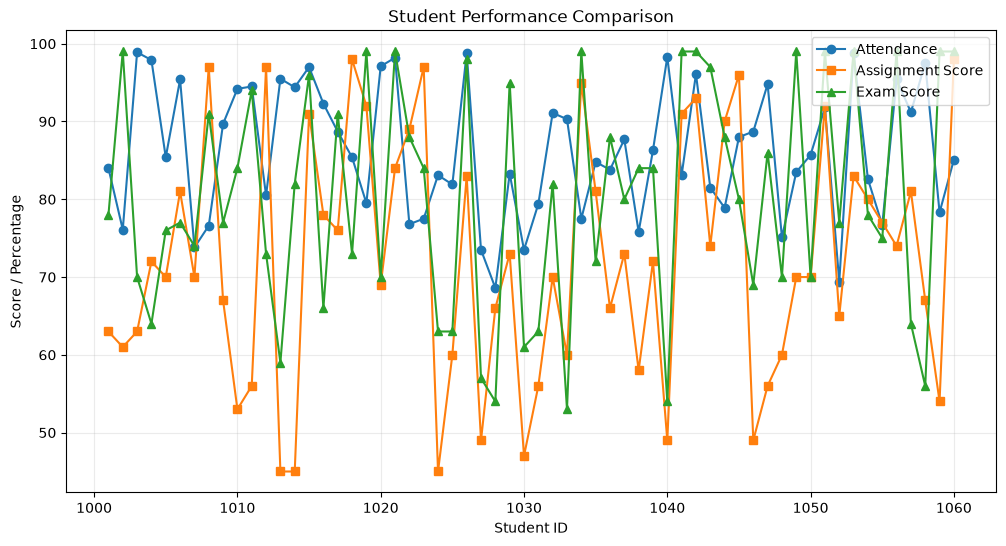

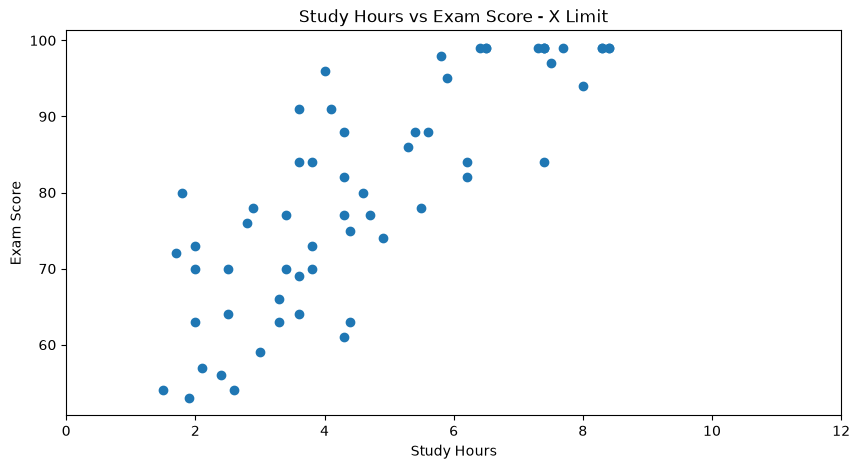

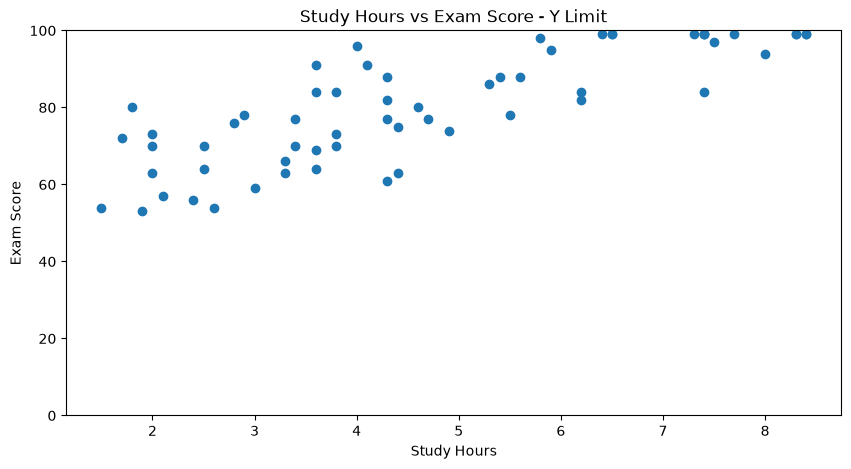

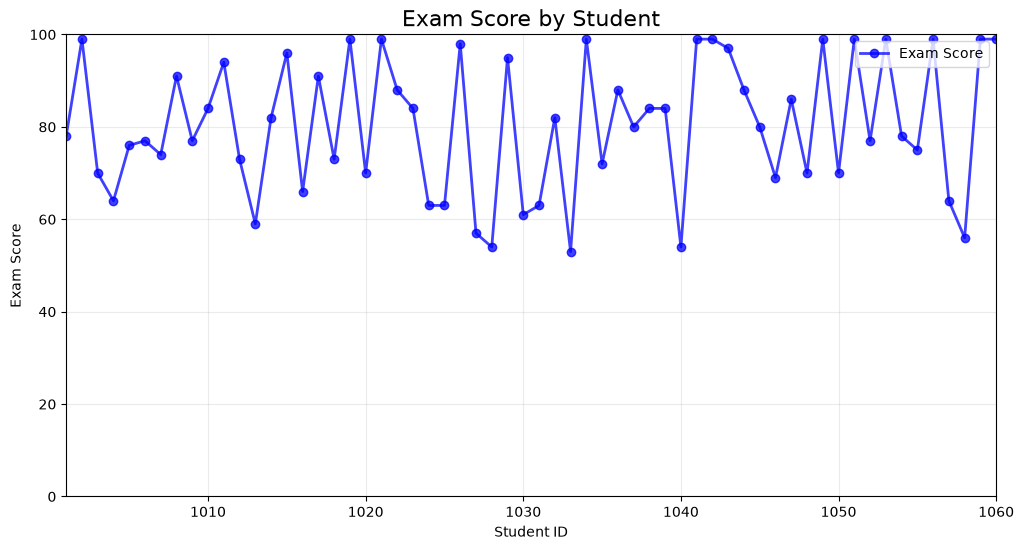

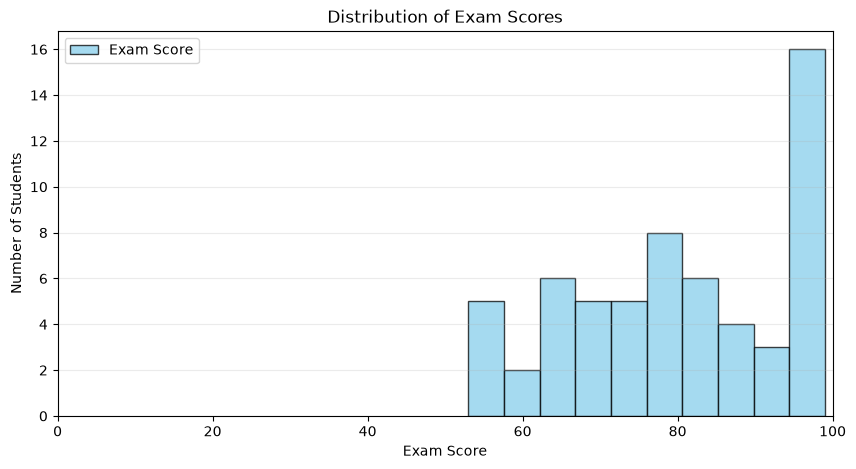

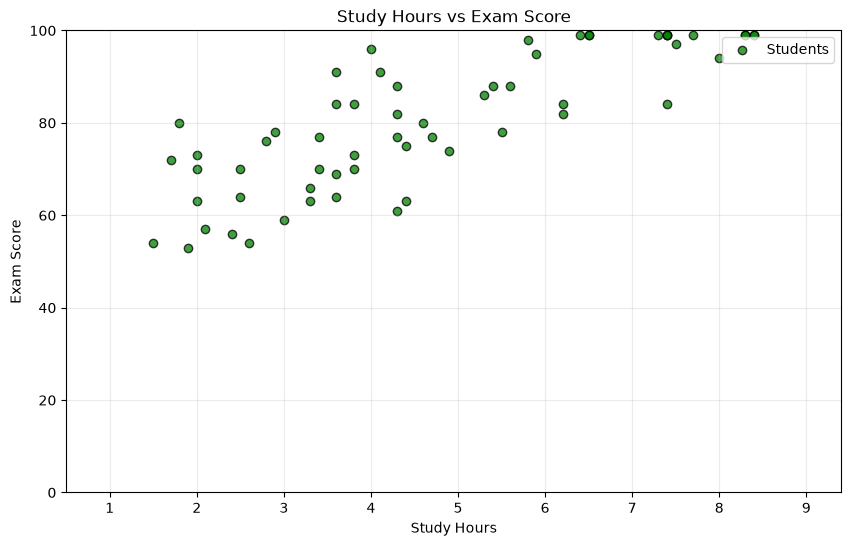

In [31]:

# ============================================================
# 7. Matplotlib Formatting Essentials
# Practical Examples Using Student Performance Dataset
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Load the cleaned dataset
# ------------------------------------------------------------

df = pd.read_csv("Student_Performance_Cleaned.csv")

# Convert date column
df["Enrollment_Date"] = pd.to_datetime(
    df["Enrollment_Date"],
    errors="coerce"
)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())


# ============================================================
# 1. figsize
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    df["Study_Hours"],
    df["Exam_Score"]
)

plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.show()


# ============================================================
# 2. marker
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    df["Study_Hours"],
    df["Exam_Score"],
    marker="o"
)

plt.title("Study Hours vs Exam Score - Marker Example")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.show()


# ============================================================
# 3. linestyle
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    df["Study_Hours"],
    df["Exam_Score"],
    marker="o",
    linestyle="--"
)

plt.title("Study Hours vs Exam Score - Dashed Line")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.show()


# ============================================================
# 4. linewidth
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    df["Study_Hours"],
    df["Exam_Score"],
    marker="o",
    linewidth=3
)

plt.title("Study Hours vs Exam Score - Line Width")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.show()


# ============================================================
# 5. alpha
# ============================================================

plt.figure(figsize=(10, 5))

plt.scatter(
    df["Study_Hours"],
    df["Exam_Score"],
    alpha=0.5
)

plt.title("Study Hours vs Exam Score - Alpha Example")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.show()


# ============================================================
# 6. label
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    df["Student_ID"],
    df["Exam_Score"],
    label="Exam Score"
)

plt.title("Exam Score by Student")
plt.xlabel("Student ID")
plt.ylabel("Exam Score")

plt.show()


# ============================================================
# 7. color
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    df["Study_Hours"],
    df["Exam_Score"],
    color="green"
)

plt.title("Study Hours vs Exam Score - Color Example")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.show()


# ============================================================
# 8. edgecolor
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["Exam_Score"],
    bins=10,
    edgecolor="black"
)

plt.title("Exam Score Distribution - Edgecolor Example")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()


# ============================================================
# 9. bins
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["Exam_Score"],
    bins=10,
    edgecolor="black"
)

plt.title("Exam Score Distribution - 10 Bins")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()


# ============================================================
# 10. rotation
# ============================================================

department_counts = df["Department"].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(
    department_counts.index,
    department_counts.values
)

plt.title("Students by Department")
plt.xlabel("Department")
plt.ylabel("Number of Students")

plt.xticks(rotation=45)

plt.show()


# ============================================================
# 11. grid()
# ============================================================

plt.figure(figsize=(10, 5))

plt.scatter(
    df["Study_Hours"],
    df["Exam_Score"]
)

plt.title("Study Hours vs Exam Score - Grid Example")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.grid(
    True,
    alpha=0.25
)

plt.show()


# ============================================================
# 12. label + legend()
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    df["Student_ID"],
    df["Attendance"],
    marker="o",
    label="Attendance"
)

plt.plot(
    df["Student_ID"],
    df["Assignment_Score"],
    marker="s",
    label="Assignment Score"
)

plt.plot(
    df["Student_ID"],
    df["Exam_Score"],
    marker="^",
    label="Exam Score"
)

plt.title("Student Performance Comparison")
plt.xlabel("Student ID")
plt.ylabel("Score / Percentage")

plt.legend(
    loc="upper right"
)

plt.grid(
    True,
    alpha=0.25
)

plt.show()


# ============================================================
# 13. xlim()
# ============================================================

plt.figure(figsize=(10, 5))

plt.scatter(
    df["Study_Hours"],
    df["Exam_Score"]
)

plt.title("Study Hours vs Exam Score - X Limit")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.xlim(0, 12)

plt.show()


# ============================================================
# 14. ylim()
# ============================================================

plt.figure(figsize=(10, 5))

plt.scatter(
    df["Study_Hours"],
    df["Exam_Score"]
)

plt.title("Study Hours vs Exam Score - Y Limit")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.ylim(0, 100)

plt.show()


# ============================================================
# 15. COMPLETE EXAMPLE
# Using multiple formatting parameters together
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    df["Student_ID"],
    df["Exam_Score"],
    marker="o",
    linestyle="-",
    linewidth=2,
    alpha=0.75,
    color="blue",
    label="Exam Score"
)

plt.title(
    "Exam Score by Student",
    fontsize=16
)

plt.xlabel("Student ID")
plt.ylabel("Exam Score")

plt.xlim(
    df["Student_ID"].min(),
    df["Student_ID"].max()
)

plt.ylim(0, 100)

plt.grid(
    True,
    alpha=0.25
)

plt.legend(
    loc="upper right"
)

plt.show()


# ============================================================
# 16. COMPLETE HISTOGRAM EXAMPLE
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["Exam_Score"],
    bins=10,
    color="skyblue",
    edgecolor="black",
    alpha=0.75,
    label="Exam Score"
)

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.xlim(0, 100)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.legend()

plt.show()


# ============================================================
# 17. COMPLETE SCATTER PLOT EXAMPLE
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Study_Hours"],
    df["Exam_Score"],
    marker="o",
    color="green",
    edgecolor="black",
    alpha=0.75,
    label="Students"
)

plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.xlim(
    df["Study_Hours"].min() - 1,
    df["Study_Hours"].max() + 1
)

plt.ylim(0, 100)

plt.grid(
    True,
    alpha=0.25
)

plt.legend()

plt.show()

# 30. EDA Interpretation Framework

Students should not stop after creating a chart.

Use this five-step framework:

### 1. What does the plot show?

Example:
> The histogram shows the distribution of Exam Scores.

### 2. What pattern do you see?

Example:
> Most students are concentrated in the middle-to-high score range.

### 3. Are there unusual values?

Example:
> A few observations appear far away from the main concentration.

### 4. What could this mean for ML?

Example:
> Score distribution should be understood before selecting transformations or scaling strategies.

### 5. What should we investigate next?

Example:
> Compare Exam Score with Study Hours and Attendance.

This converts visualization into **data-driven reasoning**.


# 31. Plot Selection by EDA Question

| EDA Question | Plot |
|---|---|
| What is the distribution? | Histogram |
| Are there outliers? | Box plot |
| How frequent are categories? | Bar chart |
| What percentage belongs to each category? | Pie chart |
| How do two numeric variables relate? | Scatter |
| How does a metric change over time? | Line |
| How do two groups compare? | Grouped bar |
| How does composition vary? | Stacked bar |
| How do multiple variables move together? | Multiple line / heatmap |
| What is the correlation? | Heatmap |
| How do 3 numerical variables interact? | 3D scatter |
| What does a numerical surface look like? | 3D surface |
| What is uncertainty/variation? | Error bar |
| How can multiple charts be compared? | Subplots |
| Where is an important observation? | Annotation |


# 32. Matplotlib Plot Types — Quick Reference

## Commonly used in ML/Data Science

### Numerical
- `plot()` → trends
- `scatter()` → relationships
- `hist()` → distributions
- `boxplot()` → outliers
- `errorbar()` → uncertainty

### Categorical
- `bar()` → category comparison
- `barh()` → horizontal category comparison
- `pie()` → composition

### Advanced
- `stem()` → individual/discrete observations
- `stackplot()` → cumulative trends
- `imshow()` → matrix/heatmap-style visualization
- 3D scatter
- 3D surface

### Layout
- `subplots()`
- `subplot()`
- `tight_layout()`

### Customization
- title
- labels
- legend
- grid
- ticks
- annotations
- figure size


# 33. End-to-End EDA Story for This Dataset

Now connect all the plots into a single EDA story.

## Step 1 — Dataset structure

We have student demographic, attendance, study and academic performance information.

## Step 2 — Univariate questions

We inspect:
- age distribution
- attendance distribution
- study-hour distribution
- assignment-score distribution
- exam-score distribution
- department frequency
- placement status

## Step 3 — Bivariate questions

We investigate:
- Study Hours → Exam Score
- Attendance → Exam Score
- Assignment Score → Exam Score
- Department → Average Exam Score
- Department + Gender → Average Exam Score

## Step 4 — Multivariate questions

We investigate:
- Study Hours + Attendance → Exam Score
- Department + Gender + Exam Score
- Department + Placement Status
- numerical correlation matrix

## Step 5 — ML preparation

The observations from EDA can guide:
- feature selection
- outlier treatment
- transformation
- encoding
- scaling
- model selection
- target selection


# 34. Mini EDA Exercise for Students

Students should answer these questions using Matplotlib.

### Exercise 1
Create a histogram of `Attendance`.

### Exercise 2
Create a box plot of `Exam_Score`.

### Exercise 3
Create a bar chart showing students by `Department`.

### Exercise 4
Create a scatter plot:
`Study_Hours` vs `Exam_Score`.

### Exercise 5
Create a scatter plot:
`Assignment_Score` vs `Exam_Score`.

### Exercise 6
Create a grouped bar chart showing average Exam Score by Department and Gender.

### Exercise 7
Create a pie chart for `Fee_Status`.

### Exercise 8
Create a stacked bar chart for Department vs Placement Status.

### Exercise 9
Create a correlation heatmap using Matplotlib `imshow()`.

### Exercise 10
Create a 3D scatter plot using:
- Study Hours
- Attendance
- Exam Score

### Exercise 11
Create a subplot containing four numerical distributions.

### Exercise 12
Find the highest Exam Score and annotate it on a scatter plot.


# 35. Important Student Questions

## Q1. Why do we perform EDA before ML?

Because a model cannot understand data quality, distributions, outliers and relationships automatically in the way a human analyst needs to.

## Q2. Does correlation mean causation?

No.

A high correlation means two variables have a strong linear association. It does not prove that one causes the other.

## Q3. When should I use a histogram?

When you want to understand the distribution of one numerical variable.

## Q4. Histogram vs bar chart?

Histogram → numerical distribution.

Bar chart → categorical comparison.

## Q5. Scatter plot vs line plot?

Scatter → relationship between observations.

Line → ordered sequence or trend, especially time.

## Q6. Why are box plots important in ML?

They can reveal unusual observations and spread before model training.

## Q7. Why learn Matplotlib before Seaborn?

Seaborn is built on Matplotlib. Understanding Matplotlib makes it easier to understand and customize Seaborn visualizations.


# 36. Best Practices

### DO

- Give every chart a meaningful title.
- Label both axes.
- Use an appropriate plot type.
- Keep charts simple.
- Use legends when necessary.
- Rotate long category labels.
- Use `tight_layout()`.
- Explain the insight after every important chart.
- Check whether the visualization actually answers a question.

### DON'T

- Use a pie chart for dozens of categories.
- Use 3D charts unnecessarily.
- Add excessive colors.
- Hide axis labels.
- Create charts without interpreting them.
- Treat correlation as causation.
- Remove outliers automatically just because they look unusual.
- Use a histogram for categorical data.


# 37. Final Matplotlib + EDA Checklist

Before finishing EDA, students should be able to answer:

### Dataset understanding
- How many rows?
- How many columns?
- Which columns are numerical?
- Which are categorical?
- Which column could be a target?

### Univariate
- What does each numerical distribution look like?
- Are there outliers?
- What categories are dominant?

### Bivariate
- Which variables appear related?
- Are there trends?
- Do groups differ?

### Multivariate
- Does the relationship change by department/gender?
- Which variables are correlated?
- Are there clusters or unusual observations?

### ML readiness
- Which features may be useful?
- Are there outliers?
- Do variables have different scales?
- Are categorical variables present?
- Is the target appropriate?

---

# 38. Conclusion

Matplotlib is not just a plotting library.

For AIML, CSE and ECE students, it is a tool for **thinking about data visually**.

The most important skill is not memorizing:

```python
plt.plot()
plt.scatter()
plt.hist()
```

The important skill is learning to ask:

> **What question am I asking about the data, and which visualization will answer that question most clearly?**

In the next session, we can take the same cleaned Student Performance dataset and learn **Seaborn**, comparing Seaborn with Matplotlib and creating statistical visualizations much more efficiently.


In [32]:
# Final verification

print("Final cleaned dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate Student IDs:", df["Student_ID"].duplicated().sum())

print("\nMatplotlib EDA session completed.")


Final cleaned dataset shape: (60, 13)
Missing values: 0
Duplicate Student IDs: 0

Matplotlib EDA session completed.
